In [14]:
import os
import pickle
from itertools import product

import numpy as np
import matplotlib.pyplot as plt

import astropy.table as at
import astropy.units as u
import astropy.coordinates as coord
from astropy.table import Table
from astropy.coordinates import SkyCoord, Distance

import jax
import jax.numpy as jnp
import jax.random as jr

import numpyro
import numpyro.distributions as dist
import numpyro.infer as infer

from scipy.stats import binned_statistic
from scipy.optimize import brentq
from tqdm import tqdm
import emcee

jax.config.update("jax_enable_x64", True)
%matplotlib inline

In [2]:
t = Table.read("astraAllStarASPCAP-0.8.fits.gz", format="fits", hdu=2)
t["sdss4_apogee_id"] = t["sdss4_apogee_id"].filled(-1)

dr17 = Table.read("allStarLite-dr17-synspec_rev1.fits", hdu=1)
t = at.join(
    t,
    dr17["APOGEE_ID", "SNR", "VHELIO_AVG"],
    keys_left="sdss4_apogee_id",
    keys_right="APOGEE_ID",
    join_type="left",
)
print("loaded t:", len(t))

from src.selection import build_prechem_selection

master_mask, sel_diag, sel_arrays = build_prechem_selection(t)
t_sel = t[master_mask]
print("pre-chem selected:", sel_diag["prechem_selected"])

loaded t: 2576187
pre-chem selected: 630079


In [4]:
from src.coords import build_galactocentric_xyz_zsun0
from src.chemistry import apply_low_alpha_cut, FEH_CUT

x, y, z = build_galactocentric_xyz_zsun0(t_sel)
chem_result = apply_low_alpha_cut(t_sel, x=x, y=y, z=z, feh_cut=FEH_CUT)

t_sel = chem_result["table"]
fe   = chem_result["fe"]
mgfe = chem_result["mgfe"]
print(f"after low-α + [Fe/H] >= {FEH_CUT}:", len(t_sel))

after low-α + [Fe/H] >= -1.2: 467098


In [5]:
feh_min_extra = -.9

extra_mask = np.asarray(fe) > feh_min_extra
t_sel = t_sel[extra_mask]
fe   = np.asarray(fe)[extra_mask]
mgfe = np.asarray(mgfe)[extra_mask]

print(f"after additional [Fe/H] > {feh_min_extra} cut:", len(t_sel))

after additional [Fe/H] > -0.9 cut: 459435


In [6]:
from src.chemistry import apply_alfe_mgmn_polygon_cut

t_final, final_diag, final_arrays = apply_alfe_mgmn_polygon_cut(t_sel)
print("t_final size:", final_diag["output_size"])

t_final size: 391384


In [162]:
from src.coords import build_star_pack_zsun0
star_pack, star_diag = build_star_pack_zsun0(t_final, rmax_keep=16, plx_min=None)

R_star    = star_pack["R_star"]
Z_star    = star_pack["Z_star"]
phi_star  = star_pack["phi_star"]
mgfe_star = star_pack["mgfe_star"]
t_star    = star_pack["t_star"]

In [8]:
from src.coords import build_segment_setup
from src.utils import col_to_float_array

segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
    phi_star, phi0=np.pi, crowd_halfwidth_deg=45, n_crowd=11
)
SEG_PLOT_heat = list(range(1, seg_diag["n_crowd"] + 1))

e_mg_h_star = col_to_float_array(t_star, "e_mg_h")
e_fe_h_star = col_to_float_array(t_star, "e_fe_h")
mgfe_err_star = np.sqrt(np.asarray(e_mg_h_star, float)**2 + np.asarray(e_fe_h_star, float)**2)

print("star_pack final size:", star_diag["final_size"])

star_pack final size: 389480


In [9]:
z_edges    = np.linspace(-3.0, 3.0, 181)
mgfe_edges = np.linspace(-0.2, 0.6, 161)
R_edges    = np.arange(0.5, 15.5 + 1.0, 1.0)

minN_seg_total   = 15
min_bin_count    = 5
min_bins_for_fit = 8
z_fit_min, z_fit_max = -1.5, 1.5
zlim = 0.6

R_centers = 0.5 * (R_edges[:-1] + R_edges[1:])

In [10]:
def mixture_of_sech2(z, A1, A2, h1, h2, z0):
    dz = z - z0
    return A1 * (1 / jnp.cosh(dz / h1)) ** 2 + A2 * (1 / jnp.cosh(dz / h2)) ** 2

def model(data):
    _A1 = numpyro.sample("_A1", dist.HalfNormal(.2))
    _A2 = numpyro.sample("_A2", dist.HalfNormal(0.2))
    A1 = numpyro.deterministic("A1", -_A1)
    A2 = numpyro.deterministic("A2", -_A2)

    h1   = numpyro.sample("h1",   dist.Uniform(0.04, 1.0))
    d_h2 = numpyro.sample("d_h2", dist.Uniform(0.04, .75))
    h2 = numpyro.deterministic("h2", h1 + d_h2)

    z0 = numpyro.sample("z0", dist.Normal(0.0, 0.2))
    offset = numpyro.sample("offset", dist.Normal(0.0, 0.2))

    model_y = mixture_of_sech2(data["z"], A1, A2, h1, h2, z0) + offset

    Q = numpyro.deterministic("Q", 0.0)
    mix = dist.Categorical(probs=jnp.array([Q, 1.0 - Q]))
    components = [
        dist.Normal(0.0, jnp.sqrt(1.0**2 + data["mg_fe_err"]**2)),
        dist.Normal(model_y, data["mg_fe_err"]),
    ]
    numpyro.sample("obs", dist.Mixture(mix, components), obs=data["mg_fe"])

In [11]:
Z_BINS_FIT = np.arange(-5, 5 + 1e-3, 0.1)

def bin_one(z, mgfe, mgfe_err, z_bins=Z_BINS_FIT):
    stat1 = binned_statistic(z, mgfe / mgfe_err**2, bins=z_bins, statistic="sum")
    stat2 = binned_statistic(z, 1 / mgfe_err**2, bins=z_bins, statistic="sum")
    stat_std = binned_statistic(z, mgfe, bins=z_bins, statistic="std")
    stat_count = binned_statistic(z, mgfe, bins=z_bins, statistic="count")

    intrinsic_scatter = stat_std.statistic / np.sqrt(stat_count.statistic)
    mean_mg_fe = stat1.statistic / stat2.statistic
    mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
    z_binc = 0.5 * (z_bins[1:] + z_bins[:-1])
    counts = stat_count.statistic
    return z_binc, mean_mg_fe, mean_mg_fe_err, counts

def fit_sech2(z_binc, mean_mg_fe, mean_mg_fe_err, key,
              num_warmup=1000, num_samples=1000, num_chains=2, progress_bar=False):
    sampler = infer.MCMC(
        infer.NUTS(model, dense_mass=True, target_accept_prob=0.95,
                   init_strategy=infer.init_to_median(num_samples=20)),
        num_warmup=num_warmup, num_samples=num_samples,
        num_chains=num_chains, progress_bar=progress_bar,
    )
    data = {
        "z": jnp.asarray(z_binc),
        "mg_fe": jnp.asarray(mean_mg_fe),
        "mg_fe_err": jnp.asarray(mean_mg_fe_err),
    }
    sampler.run(key, data=data)
    return sampler

def select_annulus_segment(R_use, Z_use, mgfe_use, mgfe_err_use, seg_mask, Rmin, Rmax,
                            min_bin_count=min_bin_count, min_bins_for_fit=min_bins_for_fit,
                            z_fit_min=z_fit_min, z_fit_max=z_fit_max):
    m = (seg_mask & (R_use >= Rmin) & (R_use < Rmax)
         & np.isfinite(Z_use) & np.isfinite(mgfe_use)
         & np.isfinite(mgfe_err_use) & (mgfe_err_use > 0))
    n_stars = int(m.sum())
    if n_stars < minN_seg_total:
        return None, None, None, n_stars, False

    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(Z_use[m], mgfe_use[m], mgfe_err_use[m])
    good = (np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
            & (counts >= min_bin_count) & (z_binc >= z_fit_min) & (z_binc <= z_fit_max))
    if good.sum() < min_bins_for_fit:
        return None, None, None, n_stars, False

    return (np.asarray(z_binc[good], float), np.asarray(mean_mg_fe[good], float),
            np.asarray(mean_mg_fe_err[good], float), n_stars, True)

In [12]:
RESULTS_PATH = "sech2_mcmc_results_zsun0_bigger_bins.pkl"
FORCE_RERUN  = True

if os.path.exists(RESULTS_PATH) and not FORCE_RERUN:
    with open(RESULTS_PATH, "rb") as f:
        saved = pickle.load(f)
    z0_med, z0_std = saved["z0_med"], saved["z0_std"]
    n_stars, n_bins, ok_grid, per_cell = saved["n_stars"], saved["n_bins"], saved["ok_grid"], saved["per_cell"]
    print(f"loaded results from {RESULTS_PATH}  ({int(ok_grid.sum())}/{ok_grid.size} cells)")
else:
    n_R, n_seg = len(R_edges) - 1, len(SEG_PLOT_heat)
    z0_med  = np.full((n_R, n_seg), np.nan)
    z0_std  = np.full((n_R, n_seg), np.nan)
    n_stars = np.zeros((n_R, n_seg), dtype=int)
    n_bins  = np.zeros((n_R, n_seg), dtype=int)
    ok_grid = np.zeros((n_R, n_seg), dtype=bool)
    per_cell = {}

    key = jr.PRNGKey(0)
    pairs = list(product(range(n_R), range(n_seg)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
        seg_id = SEG_PLOT_heat[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment(
            R_star, Z_star, mgfe_star, mgfe_err_star, seg_mask=segm[seg_id], Rmin=Rmin, Rmax=Rmax)
        n_stars[i_R, j_seg] = ns_k
        if not ok_k:
            continue
        n_bins[i_R, j_seg] = len(z_binc_k)
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()
            z0_med[i_R, j_seg] = float(np.median(samples_k["z0"]))
            z0_std[i_R, j_seg] = float(np.std(samples_k["z0"]))
            ok_grid[i_R, j_seg] = True
            per_cell[(i_R, j_seg)] = {
                "z_binc": np.asarray(z_binc_k), "mean": np.asarray(mean_k), "err": np.asarray(err_k),
                "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples_k.items()},
            }
        except Exception as e:
            print(f"  fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 10 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    print("fits complete:", int(ok_grid.sum()), "/", ok_grid.size)
    with open(RESULTS_PATH, "wb") as f:
        pickle.dump({"z0_med": z0_med, "z0_std": z0_std, "n_stars": n_stars, "n_bins": n_bins,
                     "ok_grid": ok_grid, "per_cell": per_cell, "R_edges": R_edges,
                     "SEG_PLOT_heat": SEG_PLOT_heat, "crowd_bounds": np.asarray(crowd_bounds)}, f)
    print(f"saved to {RESULTS_PATH}")

n_R, n_seg = len(R_edges) - 1, len(SEG_PLOT_heat)

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/2600209016.py:10: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/2600209016.py:11: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/2600209016.py:18: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


  done 40/165
  done 50/165
  done 60/165
  done 70/165
  done 80/165
  done 90/165
  done 100/165
  done 110/165
  done 120/165
  done 130/165
  done 140/165
  done 150/165
  done 160/165
fits complete: 121 / 165
saved to sech2_mcmc_results_zsun0_bigger_bins.pkl


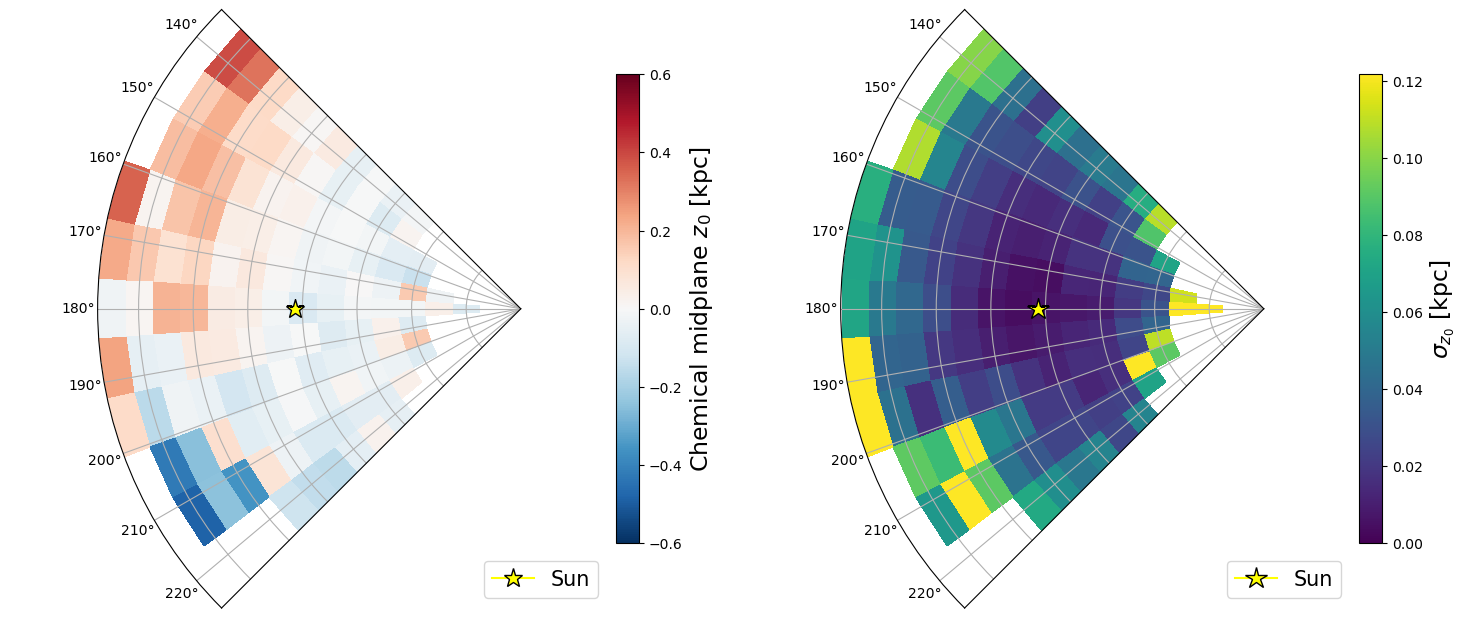

In [13]:
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi

T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
Zmap_med = np.ma.masked_invalid(z0_med)
Zmap_std = np.ma.masked_invalid(z0_std)
std_max = float(np.nanpercentile(z0_std[np.isfinite(z0_std)], 95)) if np.isfinite(z0_std).any() else 1.0
theta_min, theta_max = theta_edges[0], theta_edges[-1]
theta_sun, R_sun = np.radians(180), 8.275

fig = plt.figure(figsize=(15, 7))
ax1 = plt.subplot(1, 2, 1, projection="polar")
pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Zmap_med, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7).set_label(r"Chemical midplane $z_0$ [kpc]", fontsize=17)
ax1.set_theta_zero_location("E"); ax1.set_theta_direction(1); ax1.set_rmax(R_edges[-1])
ax1.set_thetamin(np.degrees(theta_min)); ax1.set_thetamax(np.degrees(theta_max))
ax1.set_yticklabels([])
ax1.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14, markeredgecolor="k", zorder=5, label="Sun")
ax1.legend(loc="lower right", fontsize=15)

ax2 = plt.subplot(1, 2, 2, projection="polar")
pcm2 = ax2.pcolormesh(T_mesh, R_mesh, Zmap_std, cmap="viridis", vmin=0.0, vmax=std_max, shading="flat")
fig.colorbar(pcm2, ax=ax2, pad=0.01, shrink=0.7).set_label(r"$\sigma_{z_0}$ [kpc]", fontsize=17)
ax2.set_theta_zero_location("E"); ax2.set_theta_direction(1); ax2.set_rmax(R_edges[-1])
ax2.set_thetamin(np.degrees(theta_min)); ax2.set_thetamax(np.degrees(theta_max))
ax2.set_yticklabels([])
ax2.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=16, markeredgecolor="k", zorder=5, label="Sun")
ax2.legend(loc="lower right", fontsize=15)
plt.tight_layout()
plt.show()

In [102]:
R_centers_flare = R_centers          # reuse your existing 1 kpc bin centers (cell 7)
R_width = 1.0                        # matches your R_edges spacing
n_R_flare = len(R_centers_flare)

R_arr, Z_arr, mgfe_arr, err_arr = map(np.asarray, (R_star, Z_star, mgfe_star, mgfe_err_star))
m_base = (np.isfinite(R_arr) & np.isfinite(Z_arr) & np.isfinite(mgfe_arr)
          & np.isfinite(err_arr) & (err_arr > 0))

RESULTS_PATH_FLARE = "per_R_flare_1kpc.pkl"
FORCE_RERUN_FLARE = True

if os.path.exists(RESULTS_PATH_FLARE) and not FORCE_RERUN_FLARE:
    with open(RESULTS_PATH_FLARE, "rb") as f:
        per_R_flare = pickle.load(f)
    print(f"loaded {len(per_R_flare)} fitted bins from {RESULTS_PATH_FLARE}")
else:
    per_R_flare = {}
    key = jr.PRNGKey(0)

    for i_R in tqdm(range(n_R_flare), desc="fitting radial bins"):
        Rlo, Rhi = R_centers_flare[i_R] - R_width/2, R_centers_flare[i_R] + R_width/2
        m = m_base & (R_arr >= Rlo) & (R_arr < Rhi)
        n_stars = int(m.sum())
        if n_stars < minN_seg_total:
            continue

        z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(Z_arr[m], mgfe_arr[m], err_arr[m])
        good = (np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
                & (counts >= min_bin_count) & (z_binc >= z_fit_min) & (z_binc <= z_fit_max))
        if good.sum() < min_bins_for_fit:
            continue

        try:
            key, sub = jr.split(key)
            sampler = fit_sech2(np.asarray(z_binc[good], float), np.asarray(mean_mg_fe[good], float),
                                 np.asarray(mean_mg_fe_err[good], float), sub, progress_bar=False)
            samples = sampler.get_samples()
            per_R_flare[i_R] = {"Rlo": Rlo, "Rhi": Rhi, "n_stars": n_stars,
                                 "z_binc": np.asarray(z_binc[good]), "mean": np.asarray(mean_mg_fe[good]),
                                 "err": np.asarray(mean_mg_fe_err[good]),
                                 "samples": {k: np.asarray(v) for k, v in samples.items()}}
        except Exception as e:
            print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit failed -> {e}")

    with open(RESULTS_PATH_FLARE, "wb") as f:
        pickle.dump(per_R_flare, f)
    print(f"fitted {len(per_R_flare)} / {n_R_flare} bins, saved to {RESULTS_PATH_FLARE}")

fitting radial bins:   0%|                               | 0/15 [00:00<?, ?it/s]/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/2600209016.py:10: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/2600209016.py:11: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/2600209016.py:18: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
fitting radial bins: 100%|██████████████████████| 15/15 [01:18<00:00,  5.21s/it]

fitted 15 / 15 bins, saved to per_R_flare_1kpc.pkl


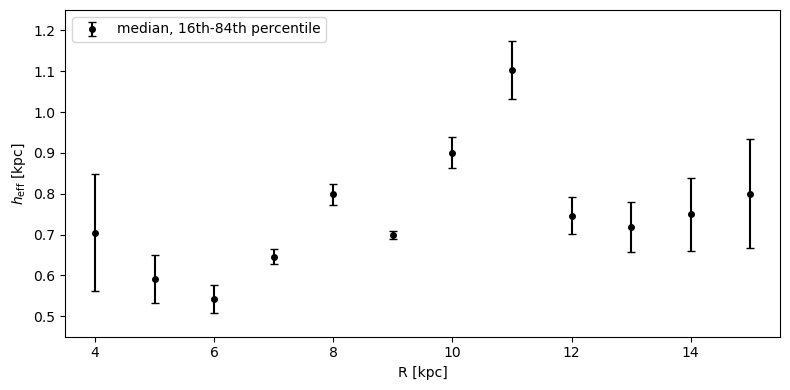

In [111]:
def root_func(z, pars):
    Ystar = mixture_of_sech2(z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], pars["z0"])
    return Ystar - 0.5 * (pars["A1"] + pars["A2"])

h_eff_med_flare = np.full(n_R_flare, np.nan)
h_eff_std_flare = np.full(n_R_flare, np.nan)

for i_R, cell in per_R_flare.items():
    s = cell["samples"]
    h_effs = []
    for i in range(256):
        cs = {k: v[i] for k, v in s.items()}
        cs["h2"] = cs["h1"] + cs["d_h2"]
        hi = 8 * max(cs["h1"], cs["h2"])
        try:
            zstar = brentq(root_func, cs["z0"] + 1e-9, hi, args=(cs,))
            h_effs.append(zstar - cs["z0"])
        except ValueError:
            continue
    if h_effs:
        h_effs = np.array(h_effs)
        h_eff_med_flare[i_R] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std_flare[i_R] = 0.5 * (pcl[1] - pcl[0])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="o", color="k", ms=4, capsize=3, label="median, 16th-84th percentile")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
# ax.set_xlim(R_centers_flare[0] - R_width/2, R_centers_flare[-1] + R_width/2)
ax.set_xlim(3.5,15.5)
ax.set_ylim(0.45,1.25)
plt.tight_layout()
plt.show()

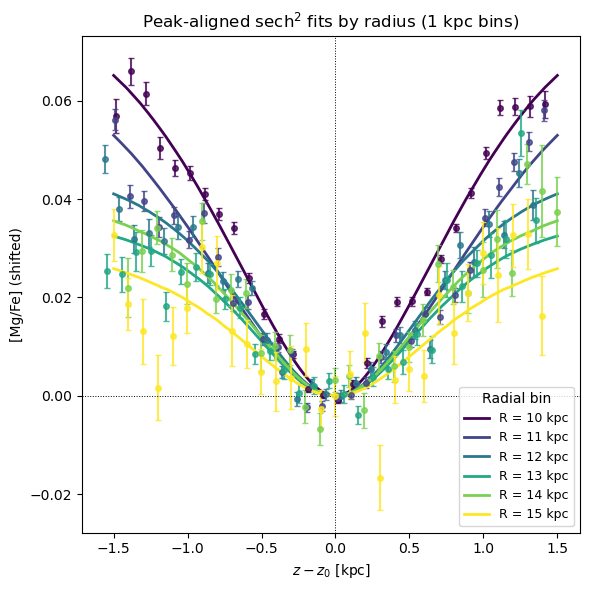

In [215]:
import matplotlib.cm as cm

R_to_show = [10, 11, 12, 13, 14, 15]
n_draws = 200

idx_to_show = [i_R for i_R in per_R_flare
               if round(R_centers_flare[i_R]) in R_to_show]
idx_to_show = sorted(idx_to_show, key=lambda i_R: R_centers_flare[i_R])

cmap = plt.get_cmap('viridis', len(idx_to_show))
colors = {i_R: cmap(k) for k, i_R in enumerate(idx_to_show)}

fig, ax = plt.subplots(figsize=(6, 6))
z_grid = np.linspace(-1.5, 1.5, 400)
rng = np.random.default_rng(0)

for i_R in idx_to_show:
    cell = per_R_flare[i_R]
    s = cell["samples"]
    n_avail = len(s["z0"])
    draw_idx = rng.choice(n_avail, size=min(n_draws, n_avail), replace=False)

    curves = []
    for i in draw_idx:
        A1 = s["A1"][i]; A2 = s["A2"][i]
        h1 = s["h1"][i]; h2 = h1 + s["d_h2"][i]
        z0 = s["z0"][i]
        peak = A1 + A2
        curves.append(mixture_of_sech2(z_grid + z0, A1, A2, h1, h2, z0) - peak)
    model_dz = np.median(curves, axis=0)     # peak-subtracted median curve

    z0_med = np.median(s["z0"])
    dz_data = cell["z_binc"] - z0_med

    # anchor the data to THIS model curve: find the single vertical shift that
    # best lines the data up with model_dz, instead of computing an independent peak
    model_at_data = np.interp(dz_data, z_grid, model_dz)
    offset = np.median(cell["mean"] - model_at_data)
    dy_data = cell["mean"] - offset

    c = colors[i_R]
    Rc = R_centers_flare[i_R]
    ax.plot(z_grid, model_dz, '-', color=c, lw=2, label=f'R = {Rc:.0f} kpc')
    ax.errorbar(dz_data, dy_data, yerr=cell["err"],
                fmt='o', color=c, ms=4, capsize=2, alpha=0.8)

ax.axhline(0, color='k', lw=0.7, ls=':')
ax.axvline(0, color='k', lw=0.7, ls=':')
ax.set_xlabel(r'$z - z_0$ [kpc]')
ax.set_ylabel(r'[Mg/Fe] (shifted)')
ax.set_title('Peak-aligned sech$^2$ fits by radius (1 kpc bins)')
ax.legend(title='Radial bin', fontsize=9)
plt.tight_layout()
plt.show()

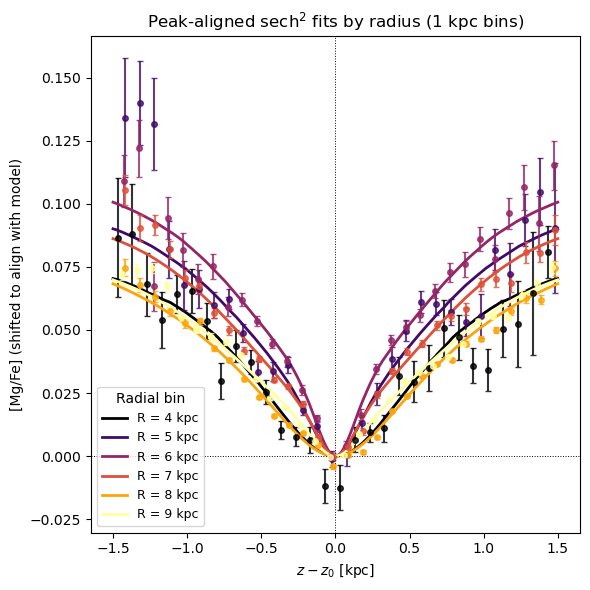

In [213]:
R_to_show = [ 4, 5, 6, 7, 8, 9]
n_draws = 200

idx_to_show = [i_R for i_R in per_R_flare
               if round(R_centers_flare[i_R]) in R_to_show]
idx_to_show = sorted(idx_to_show, key=lambda i_R: R_centers_flare[i_R])

cmap = plt.get_cmap('inferno', len(idx_to_show))
colors = {i_R: cmap(k) for k, i_R in enumerate(idx_to_show)}

fig, ax = plt.subplots(figsize=(6, 6))
z_grid = np.linspace(-1.5, 1.5, 400)
rng = np.random.default_rng(0)

for i_R in idx_to_show:
    cell = per_R_flare[i_R]
    s = cell["samples"]
    n_avail = len(s["z0"])
    draw_idx = rng.choice(n_avail, size=min(n_draws, n_avail), replace=False)

    curves = []
    for i in draw_idx:
        A1 = s["A1"][i]; A2 = s["A2"][i]
        h1 = s["h1"][i]; h2 = h1 + s["d_h2"][i]
        z0 = s["z0"][i]
        peak = A1 + A2
        curves.append(mixture_of_sech2(z_grid + z0, A1, A2, h1, h2, z0) - peak)
    model_dz = np.median(curves, axis=0)

    z0_med = np.median(s["z0"])
    dz_data = cell["z_binc"] - z0_med

    model_at_data = np.interp(dz_data, z_grid, model_dz)
    offset = np.median(cell["mean"] - model_at_data)
    dy_data = cell["mean"] - offset

    c = colors[i_R]
    Rc = R_centers_flare[i_R]
    ax.plot(z_grid, model_dz, '-', color=c, lw=2, label=f'R = {Rc:.0f} kpc')
    ax.errorbar(dz_data, dy_data, yerr=cell["err"],
                fmt='o', color=c, ms=4, capsize=2, alpha=0.8)

ax.axhline(0, color='k', lw=0.7, ls=':')
ax.axvline(0, color='k', lw=0.7, ls=':')
ax.set_xlabel(r'$z - z_0$ [kpc]')
ax.set_ylabel(r'[Mg/Fe] (shifted to align with model)')
ax.set_title('Peak-aligned sech$^2$ fits by radius (1 kpc bins)')
ax.legend(title='Radial bin', fontsize=9)
plt.tight_layout()
plt.show()

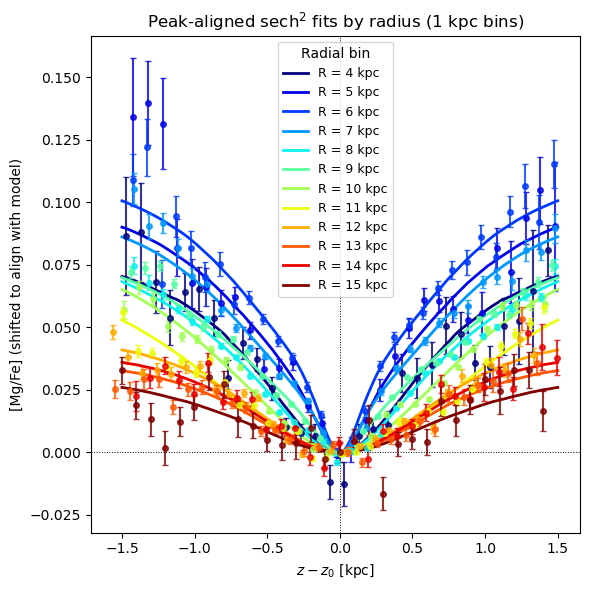

In [239]:
R_to_show = [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
n_draws = 200

idx_to_show = [i_R for i_R in per_R_flare
               if round(R_centers_flare[i_R]) in R_to_show]
idx_to_show = sorted(idx_to_show, key=lambda i_R: R_centers_flare[i_R])

cmap = plt.get_cmap('jet', len(idx_to_show))
colors = {i_R: cmap(k) for k, i_R in enumerate(idx_to_show)}

fig, ax = plt.subplots(figsize=(6, 6))
z_grid = np.linspace(-1.5, 1.5, 400)
rng = np.random.default_rng(0)

for i_R in idx_to_show:
    cell = per_R_flare[i_R]
    s = cell["samples"]
    n_avail = len(s["z0"])
    draw_idx = rng.choice(n_avail, size=min(n_draws, n_avail), replace=False)

    curves = []
    for i in draw_idx:
        A1 = s["A1"][i]; A2 = s["A2"][i]
        h1 = s["h1"][i]; h2 = h1 + s["d_h2"][i]
        z0 = s["z0"][i]
        peak = A1 + A2
        curves.append(mixture_of_sech2(z_grid + z0, A1, A2, h1, h2, z0) - peak)
    model_dz = np.median(curves, axis=0)

    z0_med = np.median(s["z0"])
    dz_data = cell["z_binc"] - z0_med

    model_at_data = np.interp(dz_data, z_grid, model_dz)
    offset = np.median(cell["mean"] - model_at_data)
    dy_data = cell["mean"] - offset

    c = colors[i_R]
    Rc = R_centers_flare[i_R]
    ax.plot(z_grid, model_dz, '-', color=c, lw=2, label=f'R = {Rc:.0f} kpc')
    ax.errorbar(dz_data, dy_data, yerr=cell["err"],
                fmt='o', color=c, ms=4, capsize=2, alpha=0.8)

ax.axhline(0, color='k', lw=0.7, ls=':')
ax.axvline(0, color='k', lw=0.7, ls=':')
ax.set_xlabel(r'$z - z_0$ [kpc]')
ax.set_ylabel(r'[Mg/Fe] (shifted to align with model)')
ax.set_title('Peak-aligned sech$^2$ fits by radius (1 kpc bins)')
ax.legend(title='Radial bin', fontsize=9)
plt.tight_layout()
plt.show()

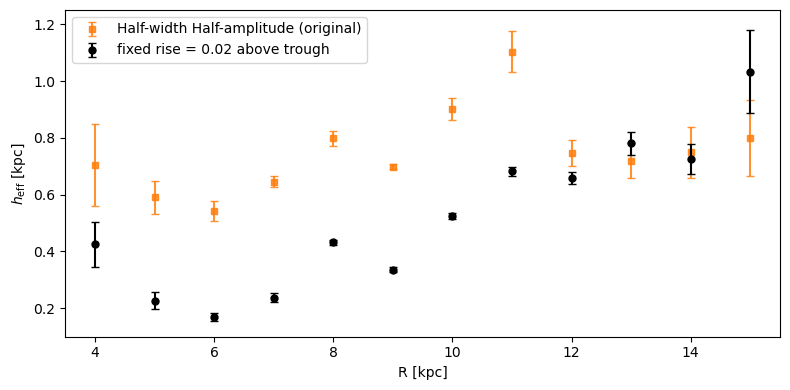

In [242]:
from scipy.optimize import brentq

DROP = 0.02 # fixed height above the trough, in [Mg/Fe]

def root_func_shifted(z, pars, drop=DROP):
    peak = pars["A1"] + pars["A2"]
    Ystar = mixture_of_sech2(z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], pars["z0"])
    return (Ystar - peak) - drop

h_eff_med_fixed = np.full(n_R_flare, np.nan)
h_eff_std_fixed = np.full(n_R_flare, np.nan)

for i_R, cell in per_R_flare.items():
    s = cell["samples"]
    n_draws = min(256, len(s["z0"]))
    h_effs = []
    for i in range(n_draws):
        cs = {k: v[i] for k, v in s.items()}
        cs["h2"] = cs["h1"] + cs["d_h2"]
        hi = 8 * max(cs["h1"], cs["h2"])
        try:
            zstar = brentq(root_func_shifted, cs["z0"] + 1e-9, hi, args=(cs,))
            h_effs.append(zstar - cs["z0"])
        except ValueError:
            continue
    if h_effs:
        h_effs = np.array(h_effs)
        h_eff_med_fixed[i_R] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std_fixed[i_R] = 0.5 * (pcl[1] - pcl[0])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="s", color="tab:orange", ms=5, capsize=3, alpha=0.85,
            label="Half-width Half-amplitude (original)", zorder=2)
ax.errorbar(R_centers_flare, h_eff_med_fixed, yerr=h_eff_std_fixed,
            fmt="o", color="k", ms=5, capsize=3,
            label=f"fixed rise = {DROP} above trough", zorder=3)
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.set_xlim(3.5, 15.5)
ax.set_ylim(0.1, 1.25)
plt.tight_layout()
plt.show()

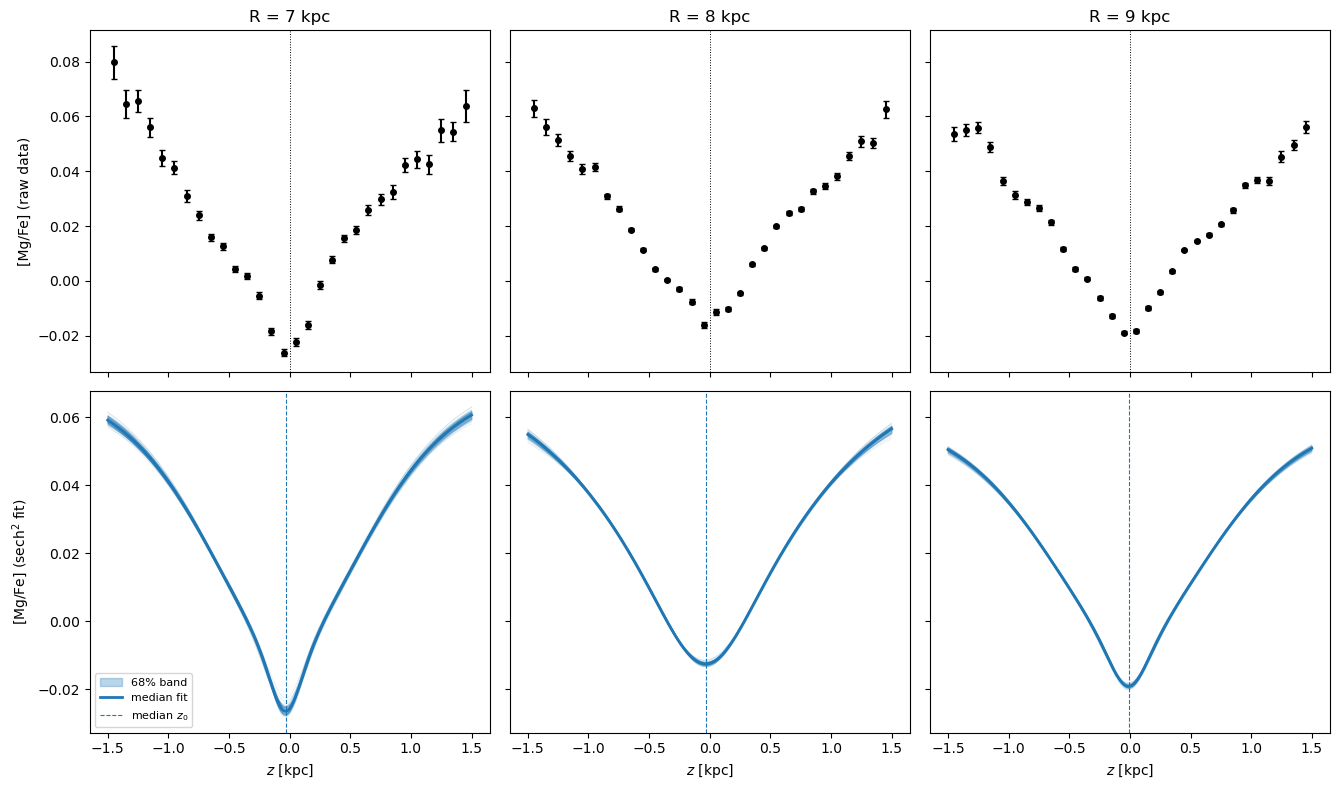

In [245]:
R_to_show = [7, 8, 9]
n_draws = 200
z_grid = np.linspace(-1.5, 1.5, 400)
rng = np.random.default_rng(0)

idx_to_show = sorted(
    [i_R for i_R in per_R_flare if round(R_centers_flare[i_R]) in R_to_show],
    key=lambda i_R: R_centers_flare[i_R],
)

fig, axes = plt.subplots(2, len(idx_to_show), figsize=(4.5 * len(idx_to_show), 8),
                         sharex=True, sharey="row", squeeze=False)

for col, i_R in enumerate(idx_to_show):
    cell = per_R_flare[i_R]
    s = cell["samples"]
    Rc = R_centers_flare[i_R]

    # ---- top row: raw binned data, no shifting, no model ----
    ax = axes[0, col]
    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                fmt="o", color="k", ms=4, capsize=2)
    ax.set_title(f"R = {Rc:.0f} kpc")
    ax.axvline(0, color="k", lw=0.7, ls=":")

    # ---- bottom row: fit only (median curve + posterior draws), actual z, actual [Mg/Fe] ----
    ax = axes[1, col]
    n_avail = len(s["z0"])
    draw_idx = rng.choice(n_avail, size=min(n_draws, n_avail), replace=False)

    curves = []
    for i in draw_idx:
        A1, A2 = s["A1"][i], s["A2"][i]
        h1 = s["h1"][i]
        h2 = h1 + s["d_h2"][i]
        z0 = s["z0"][i]
        off = s["offset"][i] if "offset" in s else 0.0
        curves.append(mixture_of_sech2(z_grid, A1, A2, h1, h2, z0) + off)
    curves = np.array(curves)

    for c in curves[:50]:
        ax.plot(z_grid, c, color="C0", lw=0.5, alpha=0.15)
    lo, hi = np.percentile(curves, [16, 84], axis=0)
    ax.fill_between(z_grid, lo, hi, color="C0", alpha=0.3, label="68% band")
    ax.plot(z_grid, np.median(curves, axis=0), color="C0", lw=2, label="median fit")
    ax.axvline(np.median(s["z0"]), color="C0", lw=0.8, ls="--", label=r"median $z_0$")
    ax.set_xlabel(r"$z$ [kpc]")

axes[0, 0].set_ylabel("[Mg/Fe] (raw data)")
axes[1, 0].set_ylabel("[Mg/Fe] (sech$^2$ fit)")
axes[1, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

R=[7.5,8.5): 90790 stars


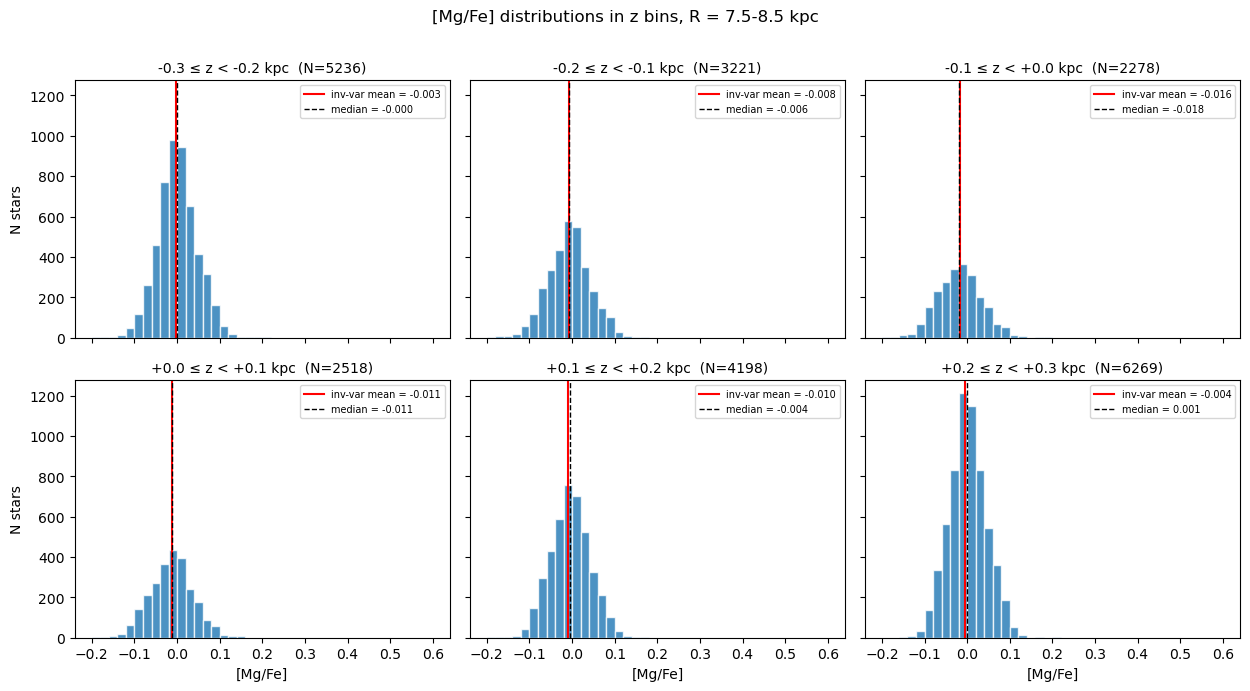

In [247]:
# ---- config ----
R_target = 8.0
z_half   = 0.3          # show z bins from -z_half to +z_half
dz       = 0.1          # z bin width (same as Z_BINS_FIT)
shift_by_z0 = False     # True: use z - z0_median(R=8 fit) so the trough is exactly at 0
mgfe_bins = np.linspace(-0.2, 0.6, 41)

i_R = int(np.argmin(np.abs(R_centers_flare - R_target)))
Rlo, Rhi = R_centers_flare[i_R] - R_width/2, R_centers_flare[i_R] + R_width/2
m = m_base & (R_arr >= Rlo) & (R_arr < Rhi)

z_use = Z_arr[m].copy()
if shift_by_z0 and i_R in per_R_flare:
    z_use = z_use - np.median(per_R_flare[i_R]["samples"]["z0"])
mg_use, err_use = mgfe_arr[m], err_arr[m]
print(f"R=[{Rlo:.1f},{Rhi:.1f}): {m.sum()} stars")

z_edges_h = np.arange(-z_half, z_half + 1e-6, dz)
n_pan = len(z_edges_h) - 1
ncols = 3
nrows = int(np.ceil(n_pan / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows),
                         sharex=True, sharey=True, squeeze=False)

for k in range(nrows * ncols):
    ax = axes.flat[k]
    if k >= n_pan:
        ax.axis("off")
        continue
    lo, hi = z_edges_h[k], z_edges_h[k + 1]
    sel = (z_use >= lo) & (z_use < hi)
    vals, errs = mg_use[sel], err_use[sel]

    ax.hist(vals, bins=mgfe_bins, color="C0", alpha=0.8, edgecolor="w")
    if sel.sum() > 1:
        w = 1 / errs**2
        mean_w = np.sum(w * vals) / np.sum(w)          # same inverse-variance mean as bin_one
        ax.axvline(mean_w, color="r", lw=1.5, label=f"inv-var mean = {mean_w:.3f}")
        ax.axvline(np.median(vals), color="k", lw=1, ls="--", label=f"median = {np.median(vals):.3f}")
        ax.legend(fontsize=7, loc="upper right")
    ax.set_title(f"{lo:+.1f} ≤ z < {hi:+.1f} kpc  (N={sel.sum()})", fontsize=10)

for ax in axes[-1]:
    ax.set_xlabel("[Mg/Fe]")
for ax in axes[:, 0]:
    ax.set_ylabel("N stars")
fig.suptitle(f"[Mg/Fe] distributions in z bins, R = {Rlo:.1f}-{Rhi:.1f} kpc", y=1.01)
plt.tight_layout()
plt.show()

In [183]:
for i_R, cell in per_R_flare.items():
    s = cell["samples"]
    amp = np.median(np.abs(s["A1"] + s["A2"]))
    Rc = R_centers_flare[i_R]
    flag = "  <-- amplitude close to DROP" if amp < 2*DROP else ""
    print(f"R = {Rc:5.1f} kpc   |amplitude| = {amp:.4f}{flag}")

R =   1.0 kpc   |amplitude| = 0.0378  <-- amplitude close to DROP
R =   2.0 kpc   |amplitude| = 0.0252  <-- amplitude close to DROP
R =   3.0 kpc   |amplitude| = 0.0707  <-- amplitude close to DROP
R =   4.0 kpc   |amplitude| = 0.0810  <-- amplitude close to DROP
R =   5.0 kpc   |amplitude| = 0.0998  <-- amplitude close to DROP
R =   6.0 kpc   |amplitude| = 0.1105
R =   7.0 kpc   |amplitude| = 0.0973  <-- amplitude close to DROP
R =   8.0 kpc   |amplitude| = 0.0844  <-- amplitude close to DROP
R =   9.0 kpc   |amplitude| = 0.0806  <-- amplitude close to DROP
R =  10.0 kpc   |amplitude| = 0.0826  <-- amplitude close to DROP
R =  11.0 kpc   |amplitude| = 0.0779  <-- amplitude close to DROP
R =  12.0 kpc   |amplitude| = 0.0469  <-- amplitude close to DROP
R =  13.0 kpc   |amplitude| = 0.0367  <-- amplitude close to DROP
R =  14.0 kpc   |amplitude| = 0.0410  <-- amplitude close to DROP
R =  15.0 kpc   |amplitude| = 0.0306  <-- amplitude close to DROP


# --- coarser azimuthal segmentation: n_crowd=5 gives ~double the bin width vs your original n_crowd=11 ---
segm_heff, crowd_bounds_heff, window_edges_heff, seg_diag_heff = build_segment_setup(
    phi_star, phi0=np.pi, crowd_halfwidth_deg=45, n_crowd=5
)
SEG_PLOT_heff = list(range(1, seg_diag_heff["n_crowd"] + 1))   # exclude the "rest" bucket at n_crowd+1

# --- fit sech^2 mixture per (R, phi) cell and extract h_eff (same root_func/brentq logic as your h_eff pipeline) ---
RESULTS_PATH_HEFF_MAP = "heff_map_1kpc_doubled_az.pkl"
FORCE_RERUN_HEFF_MAP = True

if os.path.exists(RESULTS_PATH_HEFF_MAP) and not FORCE_RERUN_HEFF_MAP:
    with open(RESULTS_PATH_HEFF_MAP, "rb") as f:
        saved = pickle.load(f)
    h_eff_med_map, h_eff_std_map = saved["h_eff_med_map"], saved["h_eff_std_map"]
    n_stars_map, ok_grid_heff = saved["n_stars_map"], saved["ok_grid_heff"]
    print(f"loaded results from {RESULTS_PATH_HEFF_MAP}  ({int(ok_grid_heff.sum())}/{ok_grid_heff.size} cells)")
else:
    n_R_heff, n_seg_heff = len(R_edges) - 1, len(SEG_PLOT_heff)
    h_eff_med_map = np.full((n_R_heff, n_seg_heff), np.nan)
    h_eff_std_map = np.full((n_R_heff, n_seg_heff), np.nan)
    n_stars_map   = np.zeros((n_R_heff, n_seg_heff), dtype=int)
    ok_grid_heff  = np.zeros((n_R_heff, n_seg_heff), dtype=bool)

    key = jr.PRNGKey(0)
    pairs = list(product(range(n_R_heff), range(n_seg_heff)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
        seg_id = SEG_PLOT_heff[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment(
            R_star, Z_star, mgfe_star, mgfe_err_star, seg_mask=segm_heff[seg_id], Rmin=Rmin, Rmax=Rmax)
        n_stars_map[i_R, j_seg] = ns_k
        if not ok_k:
            continue
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()

            h_effs = []
            for i in range(256):
                cs = {kk: vv[i] for kk, vv in samples_k.items()}
                cs["h2"] = cs["h1"] + cs["d_h2"]
                hi = 8 * max(cs["h1"], cs["h2"])
                try:
                    zstar = brentq(root_func, cs["z0"] + 1e-9, hi, args=(cs,))
                    h_effs.append(zstar - cs["z0"])
                except ValueError:
                    continue
            if h_effs:
                h_effs = np.array(h_effs)
                h_eff_med_map[i_R, j_seg] = np.median(h_effs)
                pcl = np.percentile(h_effs, [16, 84])
                h_eff_std_map[i_R, j_seg] = 0.5 * (pcl[1] - pcl[0])
                ok_grid_heff[i_R, j_seg] = True
        except Exception as e:
            print(f"  fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 10 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    print("fits complete:", int(ok_grid_heff.sum()), "/", ok_grid_heff.size)
    with open(RESULTS_PATH_HEFF_MAP, "wb") as f:
        pickle.dump({"h_eff_med_map": h_eff_med_map, "h_eff_std_map": h_eff_std_map,
                     "n_stars_map": n_stars_map, "ok_grid_heff": ok_grid_heff,
                     "R_edges": R_edges, "SEG_PLOT_heff": SEG_PLOT_heff,
                     "crowd_bounds_heff": np.asarray(crowd_bounds_heff)}, f)
    print(f"saved to {RESULTS_PATH_HEFF_MAP}")

# --- plot: same polar style as your z0 map ---
theta_edges_heff = np.unwrap(np.array(crowd_bounds_heff, float))
for i in range(1, len(theta_edges_heff)):
    while theta_edges_heff[i] <= theta_edges_heff[i - 1]:
        theta_edges_heff[i] += 2 * np.pi

T_mesh_heff, R_mesh_heff = np.meshgrid(theta_edges_heff, R_edges)
Hmap_med = np.ma.masked_invalid(h_eff_med_map)
theta_min_h, theta_max_h = theta_edges_heff[0], theta_edges_heff[-1]
theta_sun, R_sun = np.radians(180), 8.275

fig = plt.figure(figsize=(8, 7))
ax = plt.subplot(1, 1, 1, projection="polar")
pcm = ax.pcolormesh(T_mesh_heff, R_mesh_heff, Hmap_med, cmap="viridis", shading="flat")
fig.colorbar(pcm, ax=ax, pad=0.01, shrink=0.7).set_label(r"$h_\mathrm{eff}$ [kpc]", fontsize=15)
ax.set_theta_zero_location("E"); ax.set_theta_direction(1); ax.set_rmax(R_edges[-1])
ax.set_thetamin(np.degrees(theta_min_h)); ax.set_thetamax(np.degrees(theta_max_h))
ax.set_yticklabels([])
ax.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14, markeredgecolor="k", zorder=5, label="Sun")
ax.legend(loc="lower right", fontsize=12)
ax.set_title(r"$h_\mathrm{eff}$ map (doubled azimuthal bin width)", fontsize=13, pad=20)
plt.tight_layout()
plt.show()

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/2600209016.py:10: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/2600209016.py:11: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/2600209016.py:18: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


  done 10/40
  done 20/40
  done 30/40
  done 40/40
fits complete: 37 / 40
saved to heff_map_2kpc_doubled_az.pkl


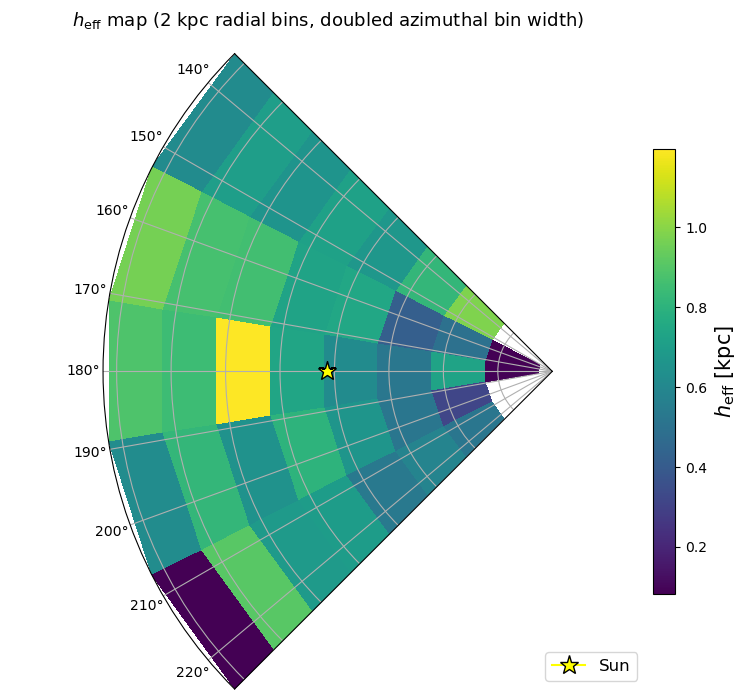

In [165]:
# --- 2 kpc radial bins (separate from your existing 1 kpc R_edges, so nothing else breaks) ---
R_edges_2kpc = np.arange(0.5, 15.5 + 2.0, 2.0)

# --- same doubled azimuthal segmentation as before ---
segm_heff, crowd_bounds_heff, window_edges_heff, seg_diag_heff = build_segment_setup(
    phi_star, phi0=np.pi, crowd_halfwidth_deg=45, n_crowd=5
)
SEG_PLOT_heff = list(range(1, seg_diag_heff["n_crowd"] + 1))

RESULTS_PATH_HEFF_MAP_2KPC = "heff_map_2kpc_doubled_az.pkl"
FORCE_RERUN_HEFF_MAP = True

if os.path.exists(RESULTS_PATH_HEFF_MAP_2KPC) and not FORCE_RERUN_HEFF_MAP:
    with open(RESULTS_PATH_HEFF_MAP_2KPC, "rb") as f:
        saved = pickle.load(f)
    h_eff_med_map, h_eff_std_map = saved["h_eff_med_map"], saved["h_eff_std_map"]
    n_stars_map, ok_grid_heff = saved["n_stars_map"], saved["ok_grid_heff"]
    print(f"loaded results from {RESULTS_PATH_HEFF_MAP_2KPC}  ({int(ok_grid_heff.sum())}/{ok_grid_heff.size} cells)")
else:
    n_R_heff, n_seg_heff = len(R_edges_2kpc) - 1, len(SEG_PLOT_heff)
    h_eff_med_map = np.full((n_R_heff, n_seg_heff), np.nan)
    h_eff_std_map = np.full((n_R_heff, n_seg_heff), np.nan)
    n_stars_map   = np.zeros((n_R_heff, n_seg_heff), dtype=int)
    ok_grid_heff  = np.zeros((n_R_heff, n_seg_heff), dtype=bool)

    key = jr.PRNGKey(0)
    pairs = list(product(range(n_R_heff), range(n_seg_heff)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin, Rmax = float(R_edges_2kpc[i_R]), float(R_edges_2kpc[i_R + 1])
        seg_id = SEG_PLOT_heff[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment(
            R_star, Z_star, mgfe_star, mgfe_err_star, seg_mask=segm_heff[seg_id], Rmin=Rmin, Rmax=Rmax)
        n_stars_map[i_R, j_seg] = ns_k
        if not ok_k:
            continue
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()

            h_effs = []
            for i in range(256):
                cs = {kk: vv[i] for kk, vv in samples_k.items()}
                cs["h2"] = cs["h1"] + cs["d_h2"]
                hi = 8 * max(cs["h1"], cs["h2"])
                try:
                    zstar = brentq(root_func, cs["z0"] + 1e-9, hi, args=(cs,))
                    h_effs.append(zstar - cs["z0"])
                except ValueError:
                    continue
            if h_effs:
                h_effs = np.array(h_effs)
                h_eff_med_map[i_R, j_seg] = np.median(h_effs)
                pcl = np.percentile(h_effs, [16, 84])
                h_eff_std_map[i_R, j_seg] = 0.5 * (pcl[1] - pcl[0])
                ok_grid_heff[i_R, j_seg] = True
        except Exception as e:
            print(f"  fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 10 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    print("fits complete:", int(ok_grid_heff.sum()), "/", ok_grid_heff.size)
    with open(RESULTS_PATH_HEFF_MAP_2KPC, "wb") as f:
        pickle.dump({"h_eff_med_map": h_eff_med_map, "h_eff_std_map": h_eff_std_map,
                     "n_stars_map": n_stars_map, "ok_grid_heff": ok_grid_heff,
                     "R_edges": R_edges_2kpc, "SEG_PLOT_heff": SEG_PLOT_heff,
                     "crowd_bounds_heff": np.asarray(crowd_bounds_heff)}, f)
    print(f"saved to {RESULTS_PATH_HEFF_MAP_2KPC}")

# --- plot ---
theta_edges_heff = np.unwrap(np.array(crowd_bounds_heff, float))
for i in range(1, len(theta_edges_heff)):
    while theta_edges_heff[i] <= theta_edges_heff[i - 1]:
        theta_edges_heff[i] += 2 * np.pi

T_mesh_heff, R_mesh_heff = np.meshgrid(theta_edges_heff, R_edges_2kpc)
Hmap_med = np.ma.masked_invalid(h_eff_med_map)
theta_min_h, theta_max_h = theta_edges_heff[0], theta_edges_heff[-1]
theta_sun, R_sun = np.radians(180), 8.275

fig = plt.figure(figsize=(8, 7))
ax = plt.subplot(1, 1, 1, projection="polar")
pcm = ax.pcolormesh(T_mesh_heff, R_mesh_heff, Hmap_med, cmap="viridis", shading="flat")
fig.colorbar(pcm, ax=ax, pad=0.01, shrink=0.7).set_label(r"$h_\mathrm{eff}$ [kpc]", fontsize=15)
ax.set_theta_zero_location("E"); ax.set_theta_direction(1); ax.set_rmax(R_edges_2kpc[-1])
ax.set_thetamin(np.degrees(theta_min_h)); ax.set_thetamax(np.degrees(theta_max_h))
ax.set_yticklabels([])
ax.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14, markeredgecolor="k", zorder=5, label="Sun")
ax.legend(loc="lower right", fontsize=12)
ax.set_title(r"$h_\mathrm{eff}$ map (2 kpc radial bins, doubled azimuthal bin width)", fontsize=13, pad=20)
plt.tight_layout()
plt.show()

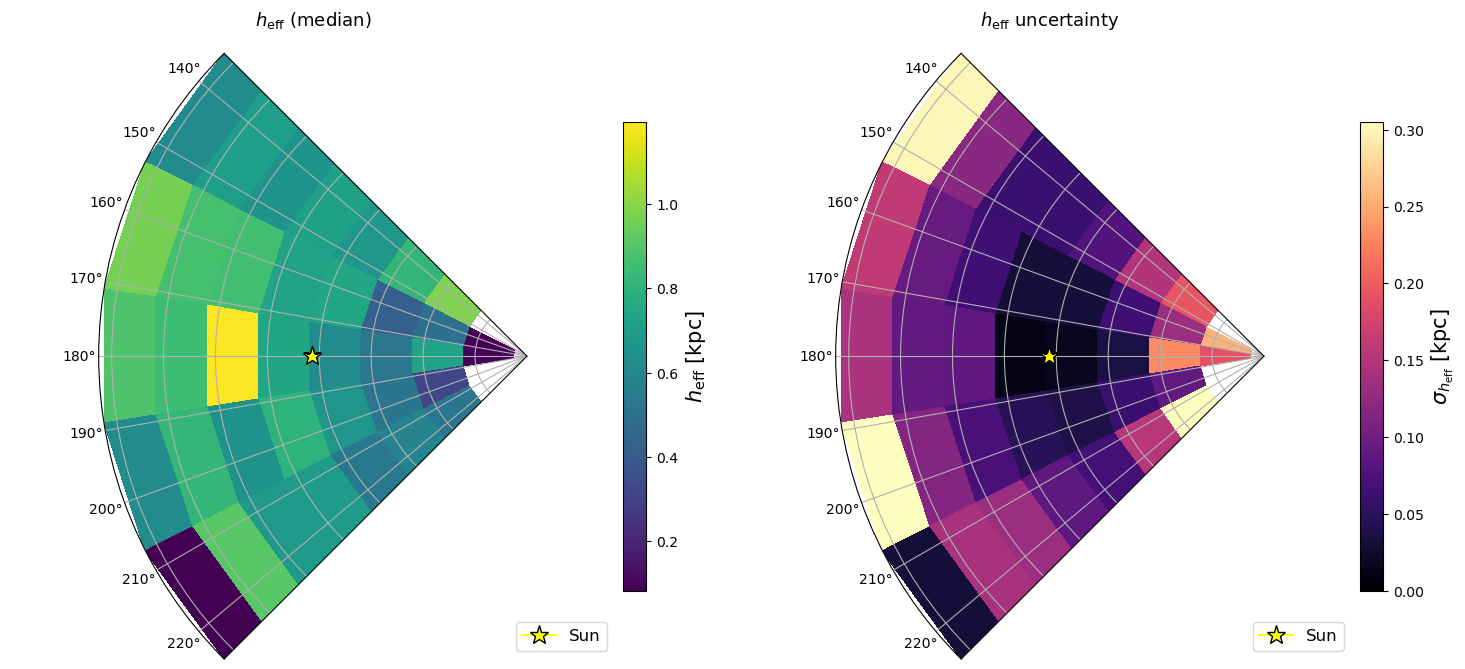

In [166]:
# --- plot: median h_eff and its uncertainty side by side ---
theta_edges_heff = np.unwrap(np.array(crowd_bounds_heff, float))
for i in range(1, len(theta_edges_heff)):
    while theta_edges_heff[i] <= theta_edges_heff[i - 1]:
        theta_edges_heff[i] += 2 * np.pi

T_mesh_heff, R_mesh_heff = np.meshgrid(theta_edges_heff, R_edges_2kpc)
Hmap_med = np.ma.masked_invalid(h_eff_med_map)
Hmap_std = np.ma.masked_invalid(h_eff_std_map)
std_max_heff = float(np.nanpercentile(h_eff_std_map[np.isfinite(h_eff_std_map)], 95)) if np.isfinite(h_eff_std_map).any() else 1.0
theta_min_h, theta_max_h = theta_edges_heff[0], theta_edges_heff[-1]
theta_sun, R_sun = np.radians(180), 8.275

fig = plt.figure(figsize=(15, 7))

ax1 = plt.subplot(1, 2, 1, projection="polar")
pcm1 = ax1.pcolormesh(T_mesh_heff, R_mesh_heff, Hmap_med, cmap="viridis", shading="flat")
fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7).set_label(r"$h_\mathrm{eff}$ [kpc]", fontsize=15)
ax1.set_theta_zero_location("E"); ax1.set_theta_direction(1); ax1.set_rmax(R_edges_2kpc[-1])
ax1.set_thetamin(np.degrees(theta_min_h)); ax1.set_thetamax(np.degrees(theta_max_h))
ax1.set_yticklabels([])
ax1.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14, markeredgecolor="k", zorder=5, label="Sun")
ax1.legend(loc="lower right", fontsize=12)
ax1.set_title(r"$h_\mathrm{eff}$ (median)", fontsize=13, pad=20)

ax2 = plt.subplot(1, 2, 2, projection="polar")
pcm2 = ax2.pcolormesh(T_mesh_heff, R_mesh_heff, Hmap_std, cmap="magma", vmin=0.0, vmax=std_max_heff, shading="flat")
fig.colorbar(pcm2, ax=ax2, pad=0.01, shrink=0.7).set_label(r"$\sigma_{h_\mathrm{eff}}$ [kpc]", fontsize=15)
ax2.set_theta_zero_location("E"); ax2.set_theta_direction(1); ax2.set_rmax(R_edges_2kpc[-1])
ax2.set_thetamin(np.degrees(theta_min_h)); ax2.set_thetamax(np.degrees(theta_max_h))
ax2.set_yticklabels([])
ax2.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14, markeredgecolor="k", zorder=5, label="Sun")
ax2.legend(loc="lower right", fontsize=12)
ax2.set_title(r"$h_\mathrm{eff}$ uncertainty", fontsize=13, pad=20)

plt.tight_layout()
plt.show()

In [24]:
import numpyro.distributions as dist
from numpyro import infer

phi_centers_seg = 0.5 * (theta_edges[:-1] + theta_edges[1:])  # same order as SEG_PLOT_heat
MIN_SEG_FOR_RING = 3  
def warp_ring_model_informed(phi, z0, z0_err, phi_ref=np.pi):
    A = numpyro.sample("A", dist.HalfNormal(0.3))
    delta_phi = numpyro.sample("delta_phi", dist.Normal(0.0, np.radians(45)))  # weakly informative
    phi_LON = numpyro.deterministic("phi_LON", phi_ref + delta_phi)
    mu = A * jnp.sin(phi - phi_LON)
    numpyro.sample("obs", dist.Normal(mu, z0_err), obs=z0)

def fit_warp_ring_informed(phi, z0, z0_err, key, phi_ref=np.pi,
                             num_warmup=1000, num_samples=1000, num_chains=2, progress_bar=False):
    sampler = infer.MCMC(
        infer.NUTS(warp_ring_model_informed, dense_mass=True, target_accept_prob=0.9),
        num_warmup=num_warmup, num_samples=num_samples,
        num_chains=num_chains, progress_bar=progress_bar,
    )
    sampler.run(key, phi=jnp.asarray(phi), z0=jnp.asarray(z0), z0_err=jnp.asarray(z0_err), phi_ref=phi_ref)
    return sampler

n_R = len(R_edges) - 1
ring_warp = {}
key = jr.PRNGKey(0)

for i_R in range(n_R):
    mask = ok_grid[i_R, :]
    n_valid = int(mask.sum())
    if n_valid < MIN_SEG_FOR_RING:
        continue

    phi_ring = phi_centers_seg[mask]
    z0_ring  = z0_med[i_R, mask]
    err_ring = z0_std[i_R, mask]
    err_ring = np.where(np.isfinite(err_ring) & (err_ring > 0), err_ring, np.nanmedian(err_ring))

    try:
        key, sub = jr.split(key)
        sampler = fit_warp_ring_informed(phi_ring, z0_ring, err_ring, sub, progress_bar=False)
        samples = sampler.get_samples()
        ring_warp[i_R] = {
            "Rlo": R_edges[i_R], "Rhi": R_edges[i_R+1], "n_seg": n_valid,
            "phi": phi_ring, "z0": z0_ring, "z0_err": err_ring,
            "samples": {k: np.asarray(v) for k, v in samples.items()},
        }
    except Exception as e:
        print(f"ring R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}]: fit failed -> {e}")

print(f"fit {len(ring_warp)}/{n_R} rings")

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/2643796579.py:15: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


fit 12/15 rings


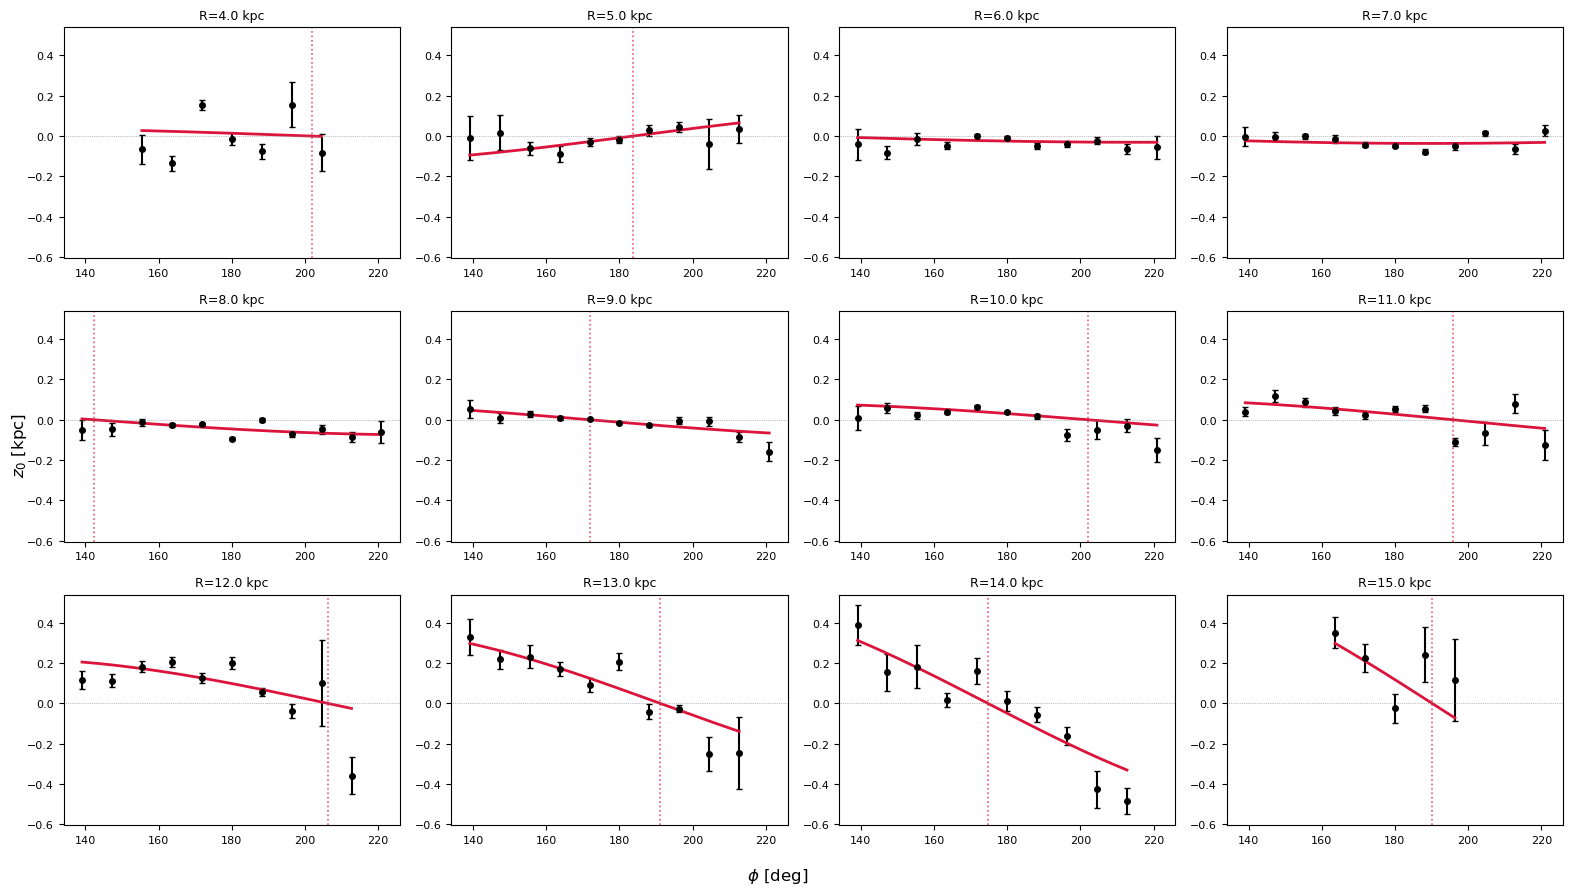

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- model ---
def sinusoid(phi, A, phi_LON):
    return A * np.sin(phi - phi_LON)

# --- assumes ring_warp already exists, built with 1 kpc radial bins ---

valid_rings = [i_R for i_R, cell in ring_warp.items() if len(cell["phi"]) >= 3]
n_rings = len(valid_rings)

ncols = 4
nrows = int(np.ceil(n_rings / ncols))

# shared x/y limits computed across all rings so panels are comparable
all_phi_deg = np.concatenate([np.degrees(ring_warp[i_R]["phi"]) for i_R in valid_rings])
all_z0 = np.concatenate([ring_warp[i_R]["z0"] for i_R in valid_rings])
all_z0_err = np.concatenate([ring_warp[i_R]["z0_err"] for i_R in valid_rings])

xlim = (all_phi_deg.min() - 5, all_phi_deg.max() + 5)
ylim = ((all_z0 - all_z0_err).min() * 1.1, (all_z0 + all_z0_err).max() * 1.1)

# --- plot ---
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=False, sharey=False)

for k, i_R in enumerate(valid_rings):
    ax = axes.flat[k]
    cell = ring_warp[i_R]

    phi = cell["phi"]
    phi_deg = np.degrees(phi)
    z0 = cell["z0"]
    z0_err = cell["z0_err"]

    ax.errorbar(phi_deg, z0, yerr=z0_err, fmt='o', color='black', ms=4, capsize=2)

    try:
        p0 = [np.ptp(z0) / 2, np.mean(phi)]
        popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                             absolute_sigma=True, maxfev=10000)
        A_fit, phiLON_fit = popt

        phi_fine = np.linspace(phi.min(), phi.max(), 500)
        mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)
        ax.plot(np.degrees(phi_fine), mu_fine, color='crimson', lw=2)

        # find zero crossings of the fit line within the observed range
        sign_changes = np.where(np.diff(np.sign(mu_fine)) != 0)[0]
        for idx in sign_changes:
            phi_a, phi_b = phi_fine[idx], phi_fine[idx + 1]
            mu_a, mu_b = mu_fine[idx], mu_fine[idx + 1]
            phi_cross = phi_a + (0 - mu_a) * (phi_b - phi_a) / (mu_b - mu_a)
            ax.axvline(np.degrees(phi_cross), color='crimson', ls=':', lw=1.2, alpha=0.7)

    except RuntimeError:
        ax.text(0.5, 0.5, "fit failed", transform=ax.transAxes,
                ha='center', va='center', fontsize=8, color='gray')

    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])
    ax.set_title(f"R={R_c:.1f} kpc", fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes.flat[n_rings:]:
    ax.axis('off')

fig.supxlabel(r"$\phi$ [deg]")
fig.supylabel(r"$z_0$ [kpc]")
plt.tight_layout()
plt.show()

In [27]:
import jax
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

POGGIO_YOUNG_GIANT = {
    "R_w": 5.5, "h_w0": 0.012, "alpha_w": 1.9,
    "phi_LON0": 0.1, "R_t": 12.1, "beta_w": 9.9,
}

def warp_model(R, phi_deg, z0_obs=None, z0_err=None):
    """Full 6-parameter model."""
    R_w = numpyro.sample("R_w", dist.Uniform(2.0, 9.0))
    h_w0 = numpyro.sample("h_w0", dist.HalfNormal(0.05))
    alpha_w = numpyro.sample("alpha_w", dist.Uniform(0.5, 3.0))
    phi_LON0 = numpyro.sample("phi_LON0", dist.Normal(0.0, 10.0))
    R_t = numpyro.sample("R_t", dist.Uniform(9.0, 15.0))
    beta_w = numpyro.sample("beta_w", dist.Normal(0.0, 15.0))

    dR = jnp.clip(R - R_w, a_min=0.0)
    h_w = jnp.where(R > R_w, h_w0 * jnp.power(dR, alpha_w), 0.0)
    phi_LON = jnp.where(R <= R_t, phi_LON0, phi_LON0 + beta_w * (R - R_t))
    z_pred = h_w * jnp.sin(jnp.deg2rad(phi_deg) - jnp.deg2rad(phi_LON))

    numpyro.deterministic("z_pred", z_pred)
    numpyro.sample("obs", dist.Normal(z_pred, z0_err), obs=z0_obs)


def warp_model_straight_LON(R, phi_deg, z0_obs=None, z0_err=None):
    """No twist term -- cross-check model."""
    R_w = POGGIO_YOUNG_GIANT["R_w"]
    h_w0 = numpyro.sample("h_w0", dist.HalfNormal(0.05))
    alpha_w = numpyro.sample("alpha_w", dist.Uniform(0.5, 4.0))
    phi_LON0 = numpyro.sample("phi_LON0", dist.Normal(0.0, 10.0))

    dR = jnp.clip(R - R_w, a_min=0.0)
    h_w = jnp.where(R > R_w, h_w0 * jnp.power(dR, alpha_w), 0.0)
    z_pred = h_w * jnp.sin(jnp.deg2rad(phi_deg) - jnp.deg2rad(phi_LON0))

    numpyro.deterministic("z_pred", z_pred)
    numpyro.sample("obs", dist.Normal(z_pred, z0_err), obs=z0_obs)

In [28]:
def run_warp_fit(model_fn, R, phi_deg, z0, z0_err, seed=0,
                  num_warmup=1500, num_samples=2000, num_chains=4):
    rng_key = jax.random.PRNGKey(seed)
    kernel = NUTS(model_fn, target_accept_prob=0.95, max_tree_depth=12)
    mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains)
    mcmc.run(rng_key, R=jnp.asarray(R), phi_deg=jnp.asarray(phi_deg),
              z0_obs=jnp.asarray(z0), z0_err=jnp.asarray(z0_err))
    mcmc.print_summary()
    return mcmc

def divergence_report(label, mcmc_obj, n_points):
    n_div = int(mcmc_obj.get_extra_fields()["diverging"].sum())
    n_total = len(mcmc_obj.get_extra_fields()["diverging"])
    pct = 100 * n_div / n_total
    print(f"{label}: {n_points} data points, {n_div}/{n_total} divergences ({pct:.1f}%)")

In [29]:
R_centers = 0.5 * (R_edges[:-1] + R_edges[1:])

theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi

phi_centers_deg_emma = np.degrees(0.5 * (theta_edges[:-1] + theta_edges[1:]))

# convert to Poggio's convention (phi=0 toward anti-centre, increasing with rotation)
phi_centers_deg = 180.0 - phi_centers_deg_emma
phi_centers_deg = (phi_centers_deg + 180) % 360 - 180

R_grid, Phi_grid = np.meshgrid(R_centers, phi_centers_deg, indexing="ij")

def extract_fit_arrays(z0_med_bin, z0_std_bin, ok_grid_bin=None, R_min=8.277, R_max=14.5):
    mask = (np.isfinite(z0_med_bin) & np.isfinite(z0_std_bin) & (z0_std_bin > 0)
            & (R_grid >= R_min) & (R_grid <= R_max))
    if ok_grid_bin is not None:
        mask &= ok_grid_bin
    return R_grid[mask], Phi_grid[mask], z0_med_bin[mask], z0_std_bin[mask]

# using your Step 8 z_sun=0 grid directly -- no "_u" suffix needed since there's no age split
R_u, phi_u, z0_u, z0err_u = extract_fit_arrays(z0_med, z0_std, ok_grid)
print(f"unified (z_sun=0): {len(z0_u)} cells going into the fit")

unified (z_sun=0): 63 cells going into the fit


In [30]:
mcmc_unified = run_warp_fit(warp_model, R_u, phi_u, z0_u, z0err_u)
samples_unified = mcmc_unified.get_samples()
divergence_report("unified (z_sun=0)", mcmc_unified, len(z0_u))

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/1170746708.py:5: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains)
sample: 100%|█| 3500/3500 [00:02<00:00, 1410.54it/s, 47 steps of size 4.40e-02. 
sample: 100%|█| 3500/3500 [00:02<00:00, 1651.09it/s, 127 steps of size 4.60e-02.
sample: 100%|█| 3500/3500 [00:02<00:00, 1663.37it/s, 47 steps of size 5.05e-02. 
sample: 100%|█| 3500/3500 [00:02<00:00, 1494.30it/s, 127 steps of size 3.96e-02.


                mean       std    median      5.0%     95.0%     n_eff     r_hat
       R_t     12.46      0.27     12.47     11.99     12.83   2530.00      1.00
       R_w      8.43      0.40      8.51      7.89      9.00   2228.91      1.00
   alpha_w      1.74      0.31      1.70      1.26      2.22   2240.13      1.00
    beta_w     16.18      3.04     15.99     11.49     20.70   2358.02      1.00
      h_w0      0.03      0.01      0.03      0.00      0.05   2501.26      1.00
  phi_LON0    -19.43      2.82    -19.32    -24.00    -14.74   3079.94      1.00

Number of divergences: 0
unified (z_sun=0): 63 data points, 0/8000 divergences (0.0%)


In [31]:
mcmc_straight = run_warp_fit(warp_model_straight_LON, R_u, phi_u, z0_u, z0err_u)
samples_straight = mcmc_straight.get_samples()
divergence_report("unified, straight LON (z_sun=0)", mcmc_straight, len(z0_u))
print("phi_LON0 (straight LON):", samples_straight["phi_LON0"].mean(),
      "+/-", samples_straight["phi_LON0"].std())

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/1170746708.py:5: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains)
sample: 100%|█| 3500/3500 [00:00<00:00, 3844.00it/s, 31 steps of size 6.63e-02. 
sample: 100%|█| 3500/3500 [00:00<00:00, 6196.72it/s, 63 steps of size 8.02e-02. 
sample: 100%|█| 3500/3500 [00:00<00:00, 6184.72it/s, 31 steps of size 7.34e-02. 
sample: 100%|█| 3500/3500 [00:00<00:00, 6400.43it/s, 47 steps of size 8.59e-02. 



                mean       std    median      5.0%     95.0%     n_eff     r_hat
   alpha_w      2.61      0.20      2.61      2.25      2.91   2080.97      1.00
      h_w0      0.00      0.00      0.00      0.00      0.00   2056.73      1.00
  phi_LON0     -7.98      1.13     -7.98     -9.83     -6.16   3160.19      1.00

Number of divergences: 0
unified, straight LON (z_sun=0): 63 data points, 0/8000 divergences (0.0%)
phi_LON0 (straight LON): -7.983335347392739 +/- 1.1277715469394243


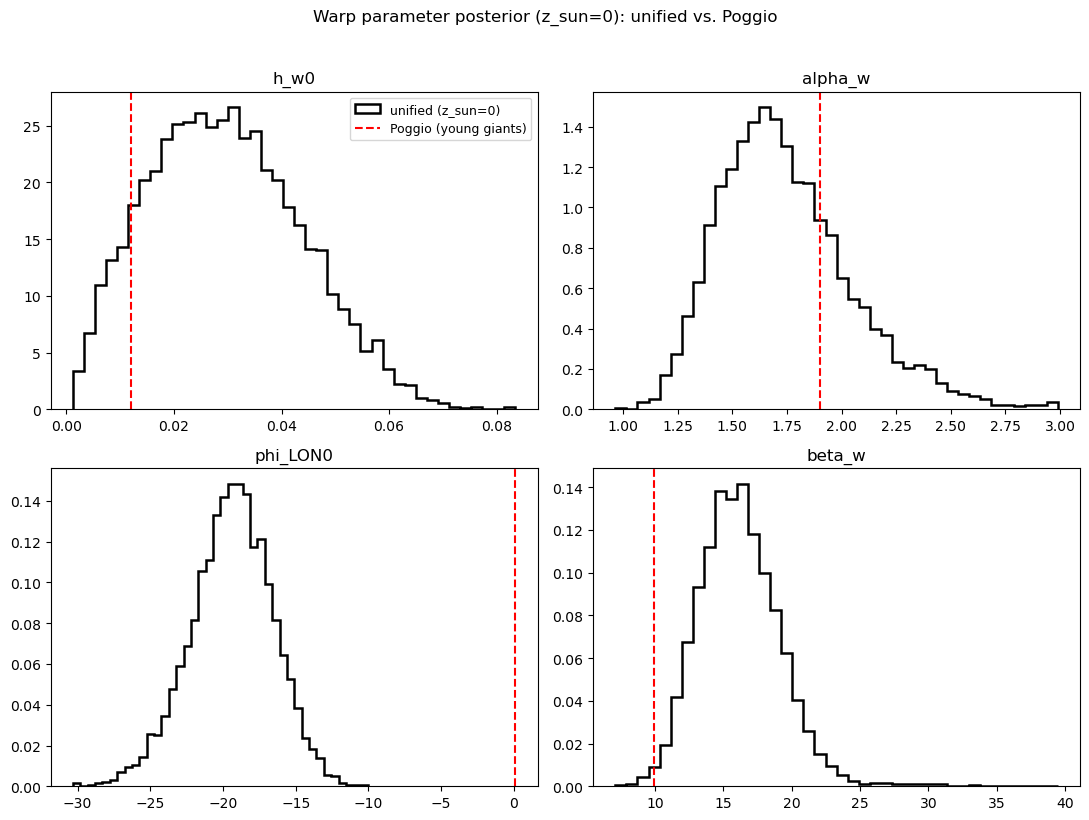

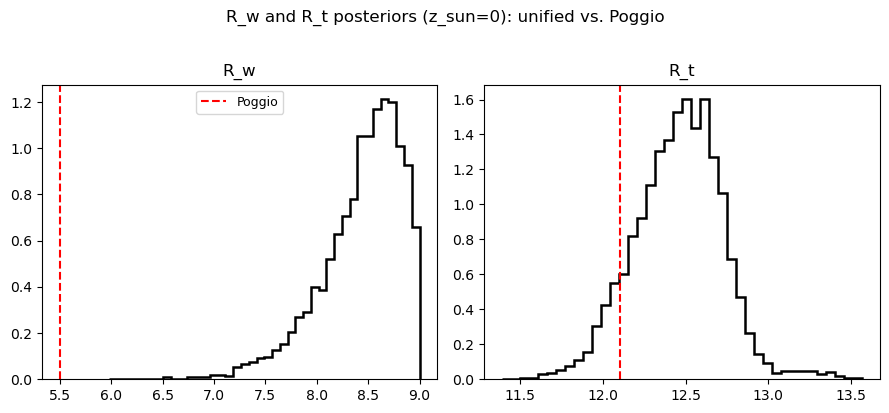

In [32]:
param_names = ["h_w0", "alpha_w", "phi_LON0", "beta_w"]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, pname in zip(axes.flat, param_names):
    ax.hist(samples_unified[pname], bins=40, density=True, histtype="step",
            color="k", label="unified (z_sun=0)", linewidth=1.8)
    ax.axvline(POGGIO_YOUNG_GIANT[pname], color="red", linestyle="--",
               linewidth=1.5, label="Poggio (young giants)" if pname == "h_w0" else None)
    ax.set_title(pname)

axes[0, 0].legend(fontsize=9)
plt.suptitle("Warp parameter posterior (z_sun=0): unified vs. Poggio", y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].hist(samples_unified["R_w"], bins=40, density=True, histtype="step", color="k", linewidth=1.8)
axes[0].axvline(POGGIO_YOUNG_GIANT["R_w"], color="red", linestyle="--", linewidth=1.5, label="Poggio")
axes[0].set_title("R_w")
axes[0].legend(fontsize=9)

axes[1].hist(samples_unified["R_t"], bins=40, density=True, histtype="step", color="k", linewidth=1.8)
axes[1].axvline(POGGIO_YOUNG_GIANT["R_t"], color="red", linestyle="--", linewidth=1.5)
axes[1].set_title("R_t")

plt.suptitle("R_w and R_t posteriors (z_sun=0): unified vs. Poggio", y=1.02)
plt.tight_layout()
plt.show()

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner

def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

# --- Eloisa's likelihood/prior, unchanged (dropped the unused R argument) ---
def lnlike(theta, z, zerr, phi):
    hw, phiw = theta
    z_model = hw * np.sin(phi - np.radians(phiw))
    sigma2 = zerr**2
    varb = (z - z_model)**2 / sigma2
    return -0.5 * np.sum(varb + np.log(sigma2))

def lnprior(theta):
    hw, phiw = theta
    if 0.0001 < hw < 0.9 and -180. < phiw < 180.:
        return 0.0
    return -np.inf

def lnprob(theta, z, zerr, phi):
    lp = lnprior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + lnlike(theta, z, zerr, phi)

# --- run per ring ---
ndim = 2
nwalkers = 100
nsteps = 2000     # <-- set to whatever Eloisa actually used; not shown in the cells she sent
burnin = 1000

emcee_results = {}

for i_R in valid_rings:
    cell = ring_warp[i_R]

    phi_emma_deg = np.degrees(cell["phi"])
    phi_eloisa_rad = np.radians(to_eloisa_frame(phi_emma_deg))   # her frame, radians

    z = cell["z0"]
    zerr = cell["z0_err"]
    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])

    p0_guess = np.array([max(np.ptp(z) / 2, 0.01), 0.0])
    pos = [p0_guess + 1e-4 * np.random.randn(ndim) for _ in range(nwalkers)]

    sampler = emcee.EnsembleSampler(nwalkers, ndim, lnprob, args=(z, zerr, phi_eloisa_rad))
    sampler.run_mcmc(pos, nsteps, progress=False)

    samples = sampler.chain[:, burnin:, :].reshape((-1, ndim))

    hw_mcmc, phiw_mcmc = map(
        lambda v: (v[1], v[2] - v[1], v[1] - v[0]),
        zip(*np.percentile(samples, [16, 50, 84], axis=0))
    )

    emcee_results[i_R] = dict(
        R_c=R_c, samples=samples,
        hw_med=hw_mcmc[0], hw_hi=hw_mcmc[1], hw_lo=hw_mcmc[2],
        phiw_med=phiw_mcmc[0], phiw_hi=phiw_mcmc[1], phiw_lo=phiw_mcmc[2],
    )

    print(f"R={R_c:.1f} kpc: hw = {hw_mcmc[0]:.3f} (+{hw_mcmc[1]:.3f}/-{hw_mcmc[2]:.3f}) kpc, "
          f"phiw = {phiw_mcmc[0]:+.1f} (+{phiw_mcmc[1]:.1f}/-{phiw_mcmc[2]:.1f}) deg [Sun at 0]")

import pickle
with open("emcee_results_1kpc.pkl", "wb") as f:
    pickle.dump(emcee_results, f)

R=4.0 kpc: hw = 0.032 (+0.043/-0.022) kpc, phiw = -41.9 (+49.0/-105.2) deg [Sun at 0]
R=5.0 kpc: hw = 0.119 (+0.047/-0.047) kpc, phiw = +173.0 (+4.7/-309.3) deg [Sun at 0]
R=6.0 kpc: hw = 0.030 (+0.010/-0.007) kpc, phiw = +61.0 (+36.4/-24.9) deg [Sun at 0]
R=7.0 kpc: hw = 0.038 (+0.006/-0.005) kpc, phiw = +81.6 (+21.4/-20.3) deg [Sun at 0]
R=8.0 kpc: hw = 0.073 (+0.013/-0.012) kpc, phiw = +38.5 (+8.8/-6.2) deg [Sun at 0]
R=9.0 kpc: hw = 0.084 (+0.015/-0.015) kpc, phiw = +8.2 (+2.4/-2.0) deg [Sun at 0]
R=10.0 kpc: hw = 0.078 (+0.018/-0.017) kpc, phiw = -23.4 (+5.9/-9.0) deg [Sun at 0]
R=11.0 kpc: hw = 0.097 (+0.020/-0.020) kpc, phiw = -16.6 (+5.5/-7.2) deg [Sun at 0]
R=12.0 kpc: hw = 0.219 (+0.029/-0.027) kpc, phiw = -27.1 (+5.0/-6.0) deg [Sun at 0]
R=13.0 kpc: hw = 0.372 (+0.040/-0.040) kpc, phiw = -11.2 (+1.9/-2.1) deg [Sun at 0]
R=14.0 kpc: hw = 0.529 (+0.058/-0.057) kpc, phiw = +5.3 (+2.1/-2.0) deg [Sun at 0]
R=15.0 kpc: hw = 0.524 (+0.217/-0.233) kpc, phiw = -14.6 (+6.9/-17.7) deg 

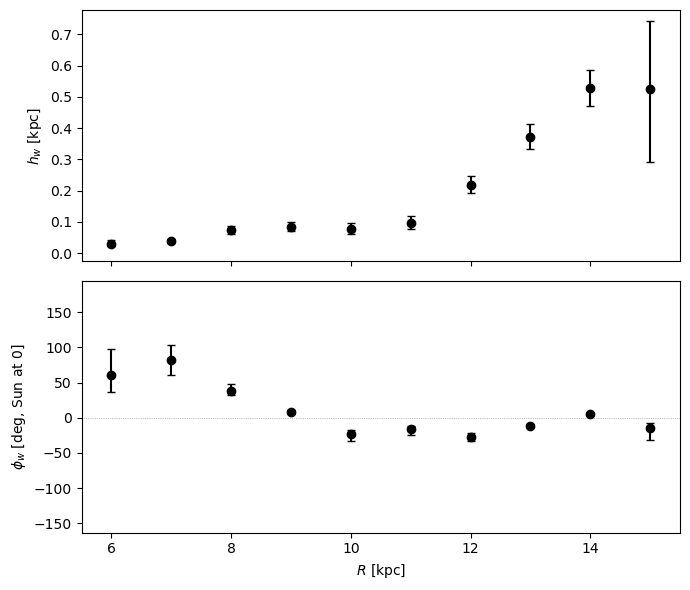

In [62]:
R_list = [emcee_results[i]["R_c"] for i in valid_rings]
hw_list = [emcee_results[i]["hw_med"] for i in valid_rings]
hw_err = [[emcee_results[i]["hw_lo"] for i in valid_rings],
          [emcee_results[i]["hw_hi"] for i in valid_rings]]
phiw_list = [emcee_results[i]["phiw_med"] for i in valid_rings]
phiw_err = [[emcee_results[i]["phiw_lo"] for i in valid_rings],
            [emcee_results[i]["phiw_hi"] for i in valid_rings]]

fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
axes[0].errorbar(R_list, hw_list, yerr=hw_err, fmt='o', color='black', capsize=3)
axes[0].set_ylabel(r"$h_w$ [kpc]")

axes[1].errorbar(R_list, phiw_list, yerr=phiw_err, fmt='o', color='black', capsize=3)
axes[1].axhline(0, color='gray', lw=0.5, ls=':')
axes[1].set_ylabel(r"$\phi_w$ [deg, Sun at 0]")
axes[1].set_xlabel(r"$R$ [kpc]")
axes[1].set_xlim(5.5,15.5)

plt.tight_layout()
plt.show()

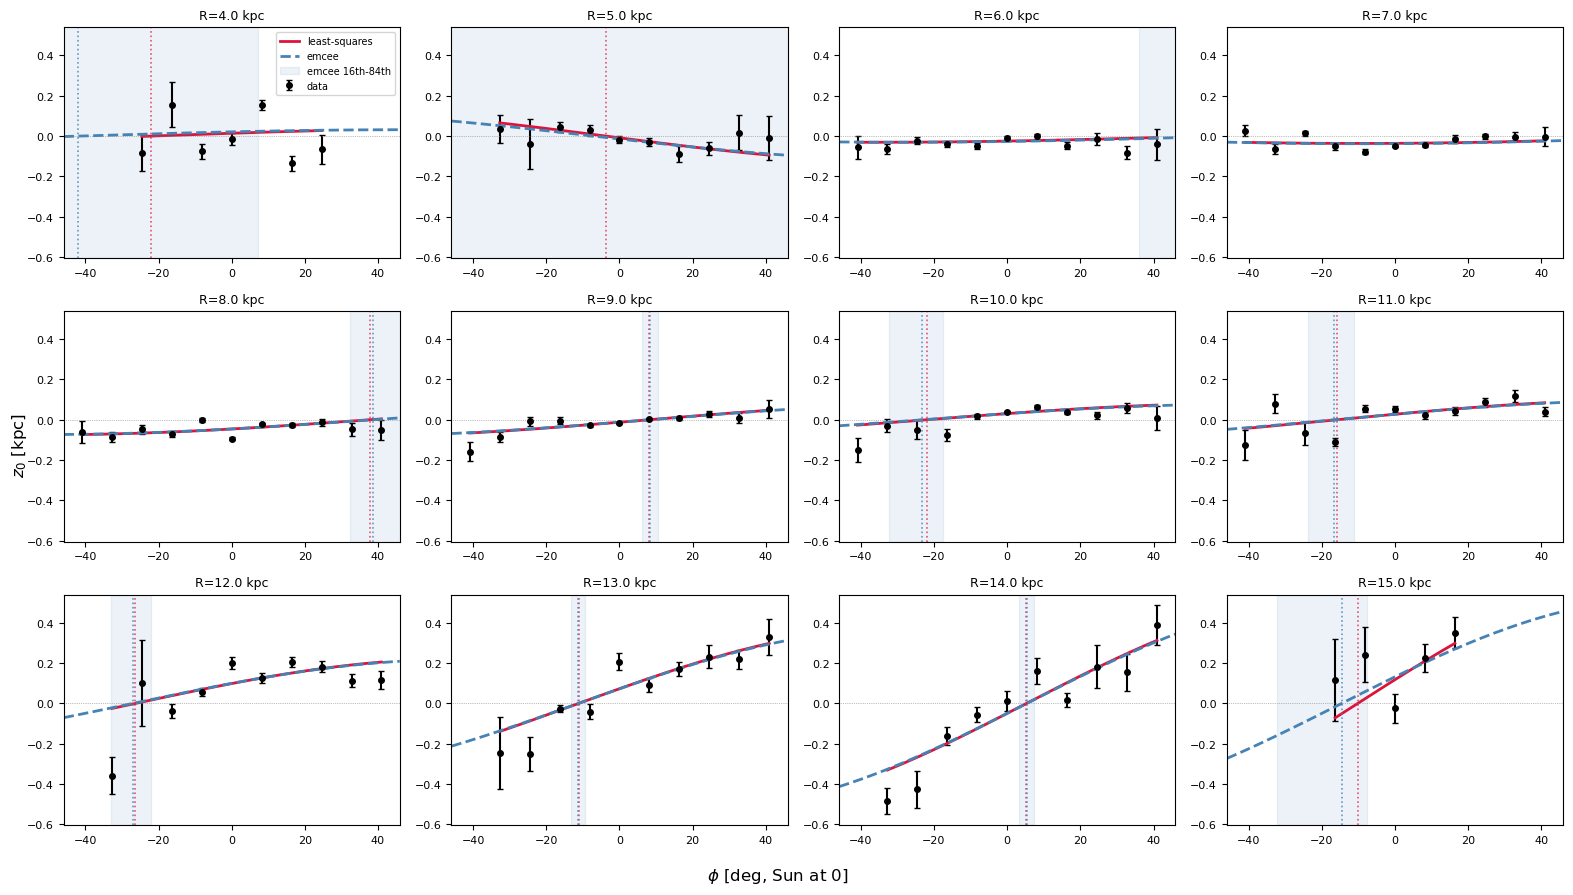

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- model ---
def sinusoid(phi, A, phi_LON):
    return A * np.sin(phi - phi_LON)

def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

valid_rings = [i_R for i_R, cell in ring_warp.items() if len(cell["phi"]) >= 3]
n_rings = len(valid_rings)

ncols = 4
nrows = int(np.ceil(n_rings / ncols))

# shared x/y limits computed across all rings, in Eloisa's frame
all_phi_deg_eloisa = np.concatenate(
    [to_eloisa_frame(np.degrees(ring_warp[i_R]["phi"])) for i_R in valid_rings]
)
all_z0 = np.concatenate([ring_warp[i_R]["z0"] for i_R in valid_rings])
all_z0_err = np.concatenate([ring_warp[i_R]["z0_err"] for i_R in valid_rings])

xlim = (all_phi_deg_eloisa.min() - 5, all_phi_deg_eloisa.max() + 5)
ylim = ((all_z0 - all_z0_err).min() * 1.1, (all_z0 + all_z0_err).max() * 1.1)

# --- plot ---
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=False, sharey=False)

for k, i_R in enumerate(valid_rings):
    ax = axes.flat[k]
    cell = ring_warp[i_R]

    phi = cell["phi"]                                   
    phi_deg_eloisa = to_eloisa_frame(np.degrees(phi))   
    z0 = cell["z0"]
    z0_err = cell["z0_err"]

    ax.errorbar(phi_deg_eloisa, z0, yerr=z0_err, fmt='o', color='black', ms=4, capsize=2,
                label='data' if k == 0 else None)

    try:
        p0 = [np.ptp(z0) / 2, np.mean(phi)]
        popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                             absolute_sigma=True, maxfev=10000)
        A_fit, phiLON_fit = popt

        phi_fine = np.linspace(phi.min(), phi.max(), 500)
        mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)
        phi_fine_deg_eloisa = to_eloisa_frame(np.degrees(phi_fine))

        ax.plot(phi_fine_deg_eloisa, mu_fine, color='crimson', lw=2,
                label='least-squares' if k == 0 else None)

        # zero crossings of the least-squares fit, in the observed window
        sign_changes = np.where(np.diff(np.sign(mu_fine)) != 0)[0]
        for idx in sign_changes:
            phi_a, phi_b = phi_fine[idx], phi_fine[idx + 1]
            mu_a, mu_b = mu_fine[idx], mu_fine[idx + 1]
            phi_cross = phi_a + (0 - mu_a) * (phi_b - phi_a) / (mu_b - mu_a)
            ax.axvline(to_eloisa_frame(np.degrees(phi_cross)),
                       color='crimson', ls=':', lw=1.2, alpha=0.7)

    except RuntimeError:
        ax.text(0.5, 0.5, "fit failed", transform=ax.transAxes,
                ha='center', va='center', fontsize=8, color='gray')

    # --- overlay the emcee fit for this ring, already in Eloisa's frame ---
    if i_R in emcee_results:
        res = emcee_results[i_R]
        hw_med = res["hw_med"]
        phiw_med = res["phiw_med"]

        phi_fine_eloisa_deg = np.linspace(xlim[0], xlim[1], 500)
        mu_emcee_fine = hw_med * np.sin(np.radians(phi_fine_eloisa_deg) - np.radians(phiw_med))
        ax.plot(phi_fine_eloisa_deg, mu_emcee_fine, color='steelblue', lw=2, ls='--',
                label='emcee' if k == 0 else None)

        ax.axvline(phiw_med, color='steelblue', ls=':', lw=1.2, alpha=0.8)
        ax.axvspan(phiw_med - res["phiw_lo"], phiw_med + res["phiw_hi"],
                   color='steelblue', alpha=0.1,
                   label='emcee 16th-84th' if k == 0 else None)

    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])
    ax.set_title(f"R={R_c:.1f} kpc", fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes.flat[n_rings:]:
    ax.axis('off')

axes.flat[0].legend(fontsize=7, loc='upper right')
fig.supxlabel(r"$\phi$ [deg, Sun at 0]")
fig.supylabel(r"$z_0$ [kpc]")
plt.tight_layout()
plt.show()

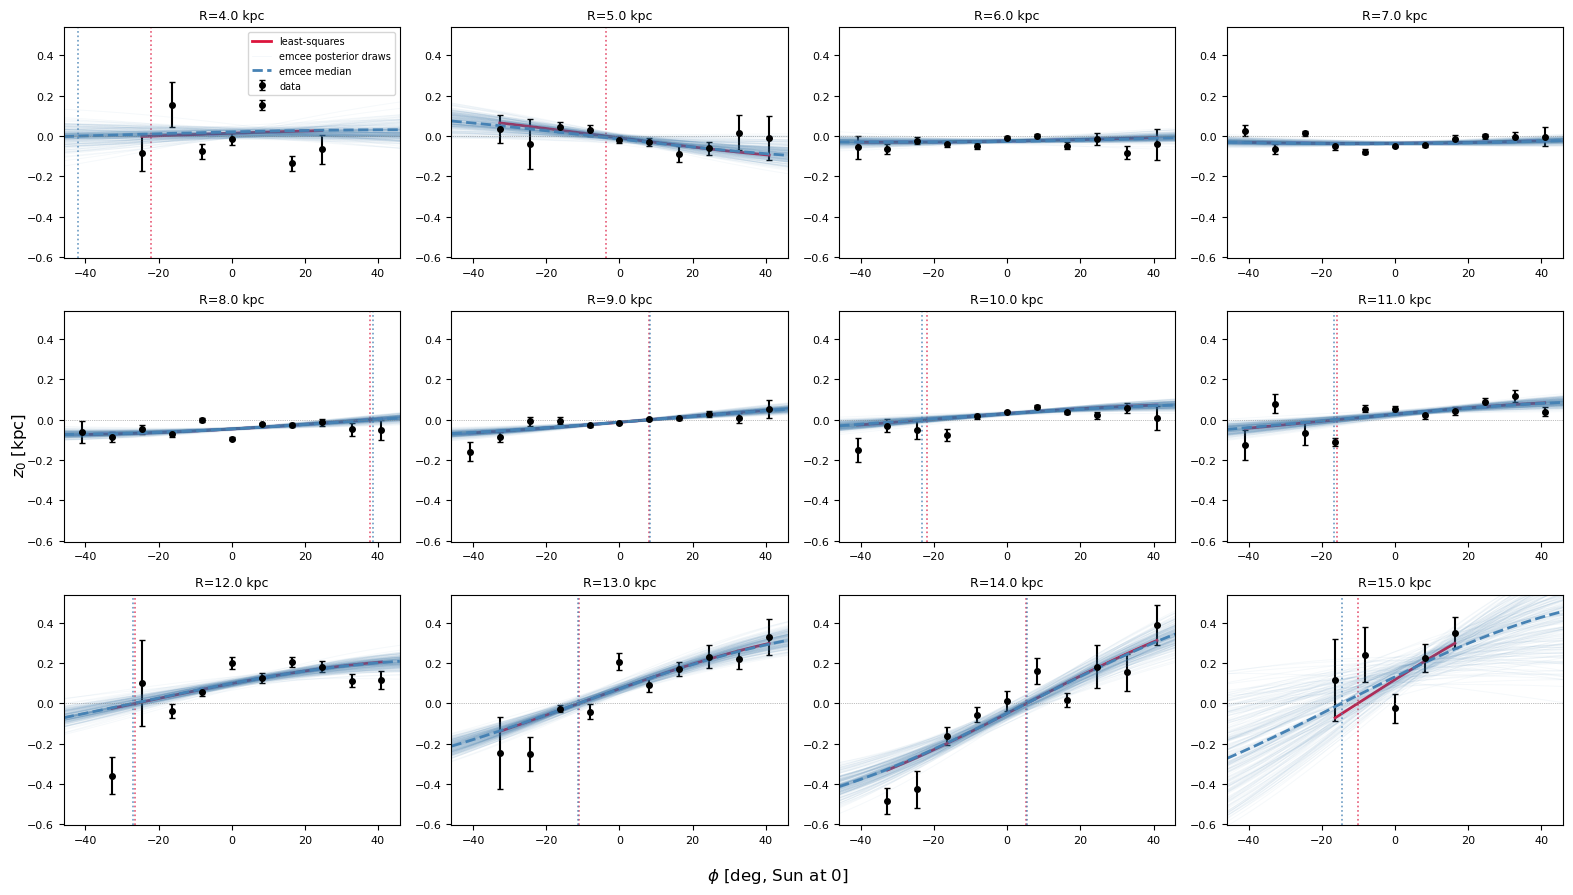

In [58]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- model ---
def sinusoid(phi, A, phi_LON):
    return A * np.sin(phi - phi_LON)

def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

valid_rings = [i_R for i_R, cell in ring_warp.items() if len(cell["phi"]) >= 3]
n_rings = len(valid_rings)

ncols = 4
nrows = int(np.ceil(n_rings / ncols))

# shared x/y limits computed across all rings, in Eloisa's frame
all_phi_deg_eloisa = np.concatenate(
    [to_eloisa_frame(np.degrees(ring_warp[i_R]["phi"])) for i_R in valid_rings]
)
all_z0 = np.concatenate([ring_warp[i_R]["z0"] for i_R in valid_rings])
all_z0_err = np.concatenate([ring_warp[i_R]["z0_err"] for i_R in valid_rings])

xlim = (all_phi_deg_eloisa.min() - 5, all_phi_deg_eloisa.max() + 5)
ylim = ((all_z0 - all_z0_err).min() * 1.1, (all_z0 + all_z0_err).max() * 1.1)

# --- plot ---
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=False, sharey=False)

for k, i_R in enumerate(valid_rings):
    ax = axes.flat[k]
    cell = ring_warp[i_R]

    phi = cell["phi"]
    phi_deg_eloisa = to_eloisa_frame(np.degrees(phi))
    z0 = cell["z0"]
    z0_err = cell["z0_err"]

    ax.errorbar(phi_deg_eloisa, z0, yerr=z0_err, fmt='o', color='black', ms=4, capsize=2,
                label='data' if k == 0 else None)

    # --- least-squares fit ---
    try:
        p0 = [np.ptp(z0) / 2, np.mean(phi)]
        popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                             absolute_sigma=True, maxfev=10000)
        A_fit, phiLON_fit = popt

        phi_fine = np.linspace(phi.min(), phi.max(), 500)
        mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)
        phi_fine_deg_eloisa = to_eloisa_frame(np.degrees(phi_fine))

        ax.plot(phi_fine_deg_eloisa, mu_fine, color='crimson', lw=2,
                label='least-squares' if k == 0 else None)

        # zero crossings of the least-squares fit, in the observed window
        sign_changes = np.where(np.diff(np.sign(mu_fine)) != 0)[0]
        for idx in sign_changes:
            phi_a, phi_b = phi_fine[idx], phi_fine[idx + 1]
            mu_a, mu_b = mu_fine[idx], mu_fine[idx + 1]
            phi_cross = phi_a + (0 - mu_a) * (phi_b - phi_a) / (mu_b - mu_a)
            ax.axvline(to_eloisa_frame(np.degrees(phi_cross)),
                       color='crimson', ls=':', lw=1.2, alpha=0.7)

    except RuntimeError:
        ax.text(0.5, 0.5, "fit failed", transform=ax.transAxes,
                ha='center', va='center', fontsize=8, color='gray')

    # --- overlay the emcee fit for this ring, already in Eloisa's frame ---
    if i_R in emcee_results:
        res = emcee_results[i_R]
        samples = res["samples"]   # shape (n_draws_total, 2): columns [hw, phiw]

        phi_fine_eloisa_deg = np.linspace(xlim[0], xlim[1], 500)
        phi_fine_eloisa_rad = np.radians(phi_fine_eloisa_deg)

        # random posterior draws, shown as a translucent spaghetti/shading band
        n_draws = 200
        rng = np.random.default_rng(0)
        draw_idx = rng.choice(len(samples), size=min(n_draws, len(samples)), replace=False)

        for j, idx in enumerate(draw_idx):
            hw_draw, phiw_draw = samples[idx]
            mu_draw = hw_draw * np.sin(phi_fine_eloisa_rad - np.radians(phiw_draw))
            ax.plot(phi_fine_eloisa_deg, mu_draw, color='steelblue', lw=0.7, alpha=0.05,
                     label='emcee posterior draws' if (k == 0 and j == 0) else None)

        # median curve on top, for reference
        hw_med = res["hw_med"]
        phiw_med = res["phiw_med"]
        mu_med = hw_med * np.sin(phi_fine_eloisa_rad - np.radians(phiw_med))
        ax.plot(phi_fine_eloisa_deg, mu_med, color='steelblue', lw=2, ls='--',
                label='emcee median' if k == 0 else None)

        ax.axvline(phiw_med, color='steelblue', ls=':', lw=1.2, alpha=0.8)

    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])
    ax.set_title(f"R={R_c:.1f} kpc", fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes.flat[n_rings:]:
    ax.axis('off')

axes.flat[0].legend(fontsize=7, loc='upper right')
fig.supxlabel(r"$\phi$ [deg, Sun at 0]")
fig.supylabel(r"$z_0$ [kpc]")
plt.tight_layout()
plt.show()

In [46]:
import numpy as np
import matplotlib.pyplot as plt

def plot_phiw_histograms(results, title_suffix=""):
    valid = sorted(results.keys())
    n_rings = len(valid)
    ncols = 4
    nrows = int(np.ceil(n_rings / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=True)

    for k, i_R in enumerate(valid):
        ax = axes.flat[k]
        res = results[i_R]
        phiw_draws = res["samples"][:, 1]   # column 1 = phiw, already Eloisa frame, degrees

        ax.hist(phiw_draws, bins=60, color='steelblue', alpha=0.7, density=True)
        ax.axvline(res["phiw_med"], color='crimson', ls='--', lw=1.5)
        ax.set_title(f"R={res['R_c']:.1f} kpc", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.set_yticks([])

    for ax in axes.flat[n_rings:]:
        ax.axis('off')

    fig.supxlabel(r"$\phi_w$ [deg, Sun at 0]")
    fig.suptitle(f"emcee $\\phi_w$ posteriors {title_suffix}", y=1.02)
    plt.tight_layout()
    plt.show()

def plot_hw_histograms(results, title_suffix=""):
    valid = sorted(results.keys())
    n_rings = len(valid)
    ncols = 4
    nrows = int(np.ceil(n_rings / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=True)

    for k, i_R in enumerate(valid):
        ax = axes.flat[k]
        res = results[i_R]
        hw_draws = res["samples"][:, 0]   # column 0 = hw

        ax.hist(hw_draws, bins=60, color='seagreen', alpha=0.7, density=True)
        ax.axvline(res["hw_med"], color='crimson', ls='--', lw=1.5)
        ax.set_title(f"R={res['R_c']:.1f} kpc", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.set_yticks([])

    for ax in axes.flat[n_rings:]:
        ax.axis('off')

    fig.supxlabel(r"$h_w$ [kpc]")
    fig.suptitle(f"emcee $h_w$ posteriors {title_suffix}", y=1.02)
    plt.tight_layout()
    plt.show()

In [51]:
import pickle

with open("emcee_results_1kpc.pkl", "rb") as f:
    emcee_results_1kpc = pickle.load(f)

with open("emcee_results_05kpc.pkl", "rb") as f:
    emcee_results_05kpc = pickle.load(f)

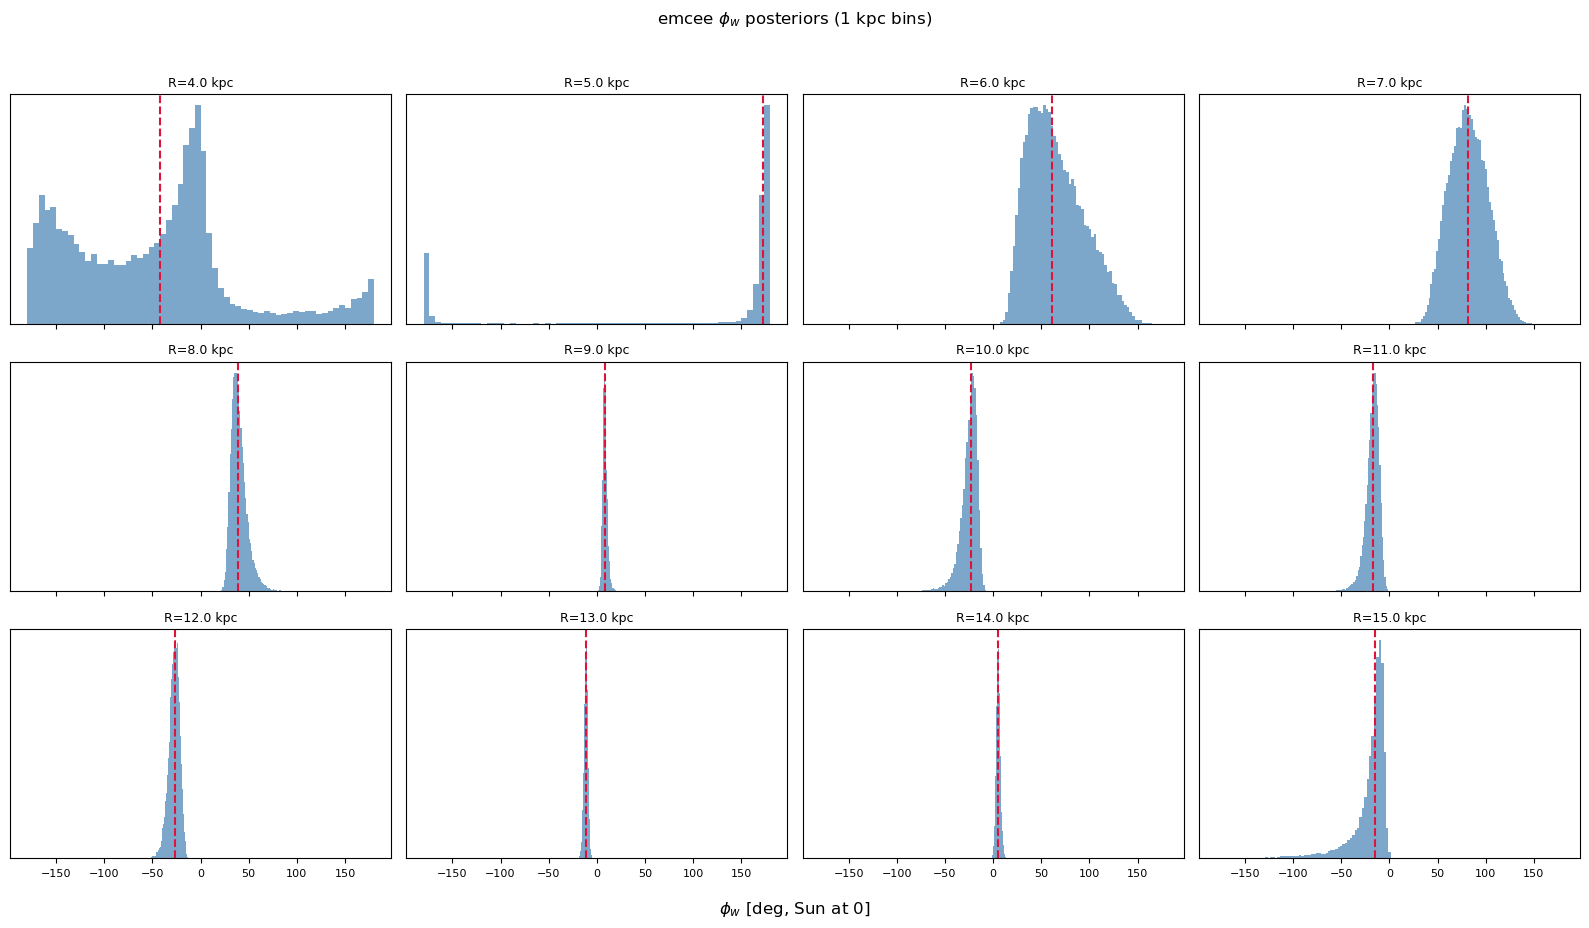

In [53]:
plot_phiw_histograms(emcee_results_1kpc, title_suffix="(1 kpc bins)")

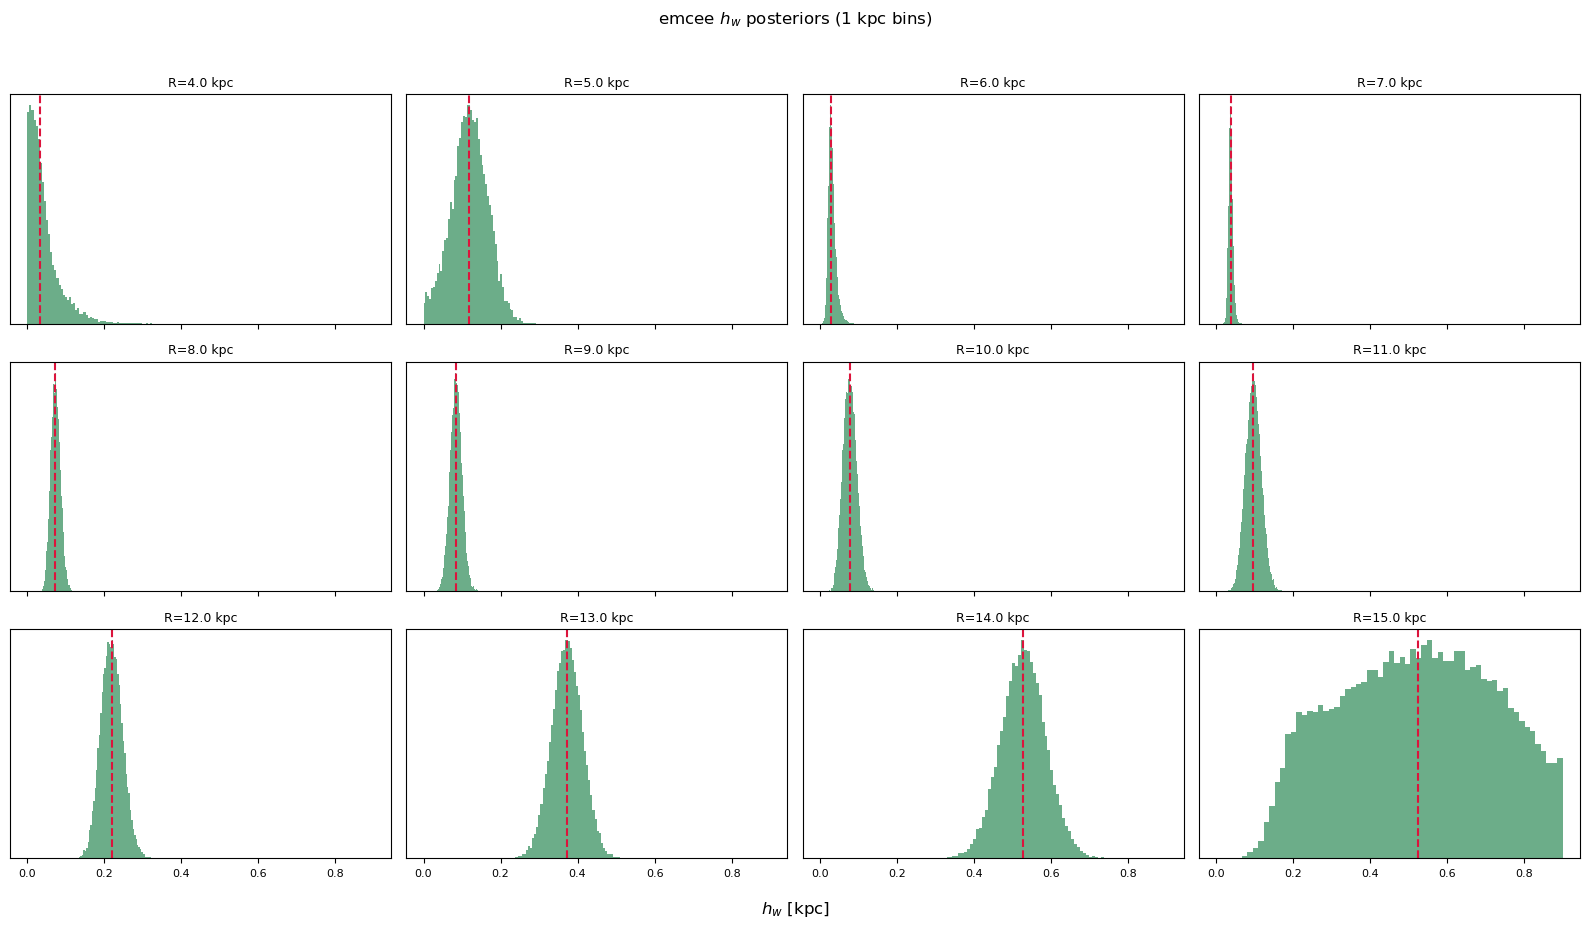

In [54]:
plot_hw_histograms(emcee_results_1kpc, title_suffix="(1 kpc bins)")

In [66]:
def paper_phi_to_sun0_frame(phi_paper_deg):
    return ((np.asarray(phi_paper_deg) + 180.0) % 360.0) - 180.0

In [67]:
# --- Young giants (Table 1) ---
yg = dict(R_w=5.5, h_w0=0.012, alpha_w=1.9, phiLON0=0.1, R_t=12.1, beta_w=9.9)
yg_straight_phiLON = 9.9   # deg, paper frame, +/- 0.6

# --- Cepheids (Table 2) ---
ceph = dict(R_w=7.7, h_w0=0.057, alpha_w=1.3, phiLON0=0.9, R_t=12.6, beta_w=8.0)
ceph_straight_phiLON = 14.0   # deg, paper frame, +/- 0.6

def h_w_paper(R, R_w, h_w0, alpha_w):
    return np.where(R > R_w, h_w0 * np.clip(R - R_w, 0, None)**alpha_w, 0.0)

def phiLON_paper(R, phiLON0, R_t, beta_w):
    return np.where(R <= R_t, phiLON0, phiLON0 + beta_w * (R - R_t))

In [75]:
R_grid_yg = np.linspace(9, 14.5, 300)     # young giants: paper's own R limit
R_grid_ceph = np.linspace(9, 16.5, 300)   # Cepheids: paper's own R limit

hw_med_yg, hw_lo_yg, hw_hi_yg, phi_med_yg, phi_lo_yg, phi_hi_yg = band_for_sample(yg_params, R_grid_yg, seed=1)
hw_med_ceph, hw_lo_ceph, hw_hi_ceph, phi_med_ceph, phi_lo_ceph, phi_hi_ceph = band_for_sample(ceph_params, R_grid_ceph, seed=2)

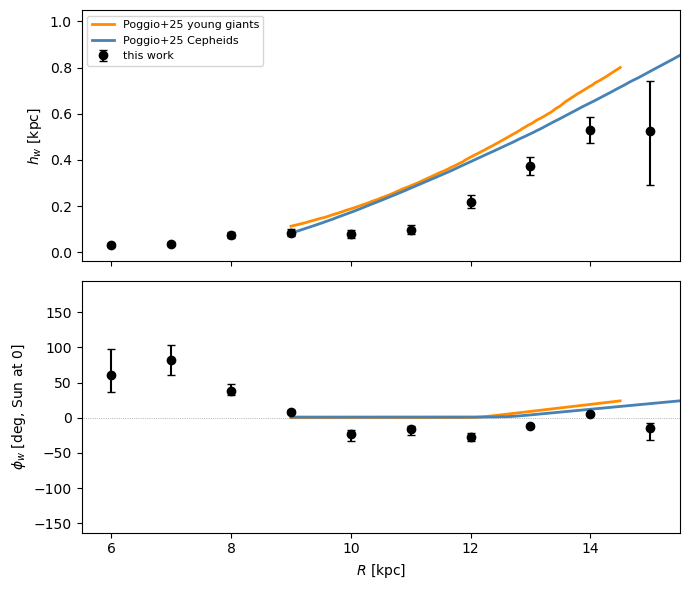

In [78]:
fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

axes[0].errorbar(R_list, hw_list, yerr=hw_err, fmt='o', color='black', capsize=3, label='this work')
axes[0].plot(R_grid_yg, hw_med_yg, color='darkorange', lw=2, label='Poggio+25 young giants')
axes[0].plot(R_grid_ceph, hw_med_ceph, color='steelblue', lw=2, label='Poggio+25 Cepheids')
axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[0].legend(fontsize=8)

axes[1].errorbar(R_list, phiw_list, yerr=phiw_err, fmt='o', color='black', capsize=3)
axes[1].plot(R_grid_yg, phi_med_yg, color='darkorange', lw=2)
axes[1].plot(R_grid_ceph, phi_med_ceph, color='steelblue', lw=2)
axes[1].axhline(0, color='gray', lw=0.5, ls=':')
axes[1].set_ylabel(r"$\phi_w$ [deg, Sun at 0]")
axes[1].set_xlabel(r"$R$ [kpc]")
axes[1].set_xlim(5.5, 15.5)

plt.tight_layout()
plt.show()

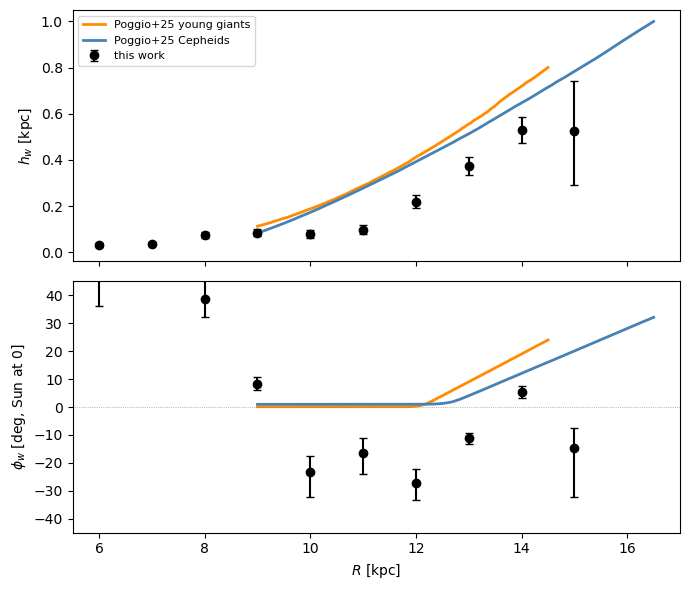

In [82]:
fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

axes[0].errorbar(R_list, hw_list, yerr=hw_err, fmt='o', color='black', capsize=3, label='this work')
axes[0].plot(R_grid_yg, hw_med_yg, color='darkorange', lw=2, label='Poggio+25 young giants')
axes[0].plot(R_grid_ceph, hw_med_ceph, color='steelblue', lw=2, label='Poggio+25 Cepheids')
axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[0].legend(fontsize=8)

axes[1].errorbar(R_list, phiw_list, yerr=phiw_err, fmt='o', color='black', capsize=3)
axes[1].plot(R_grid_yg, phi_med_yg, color='darkorange', lw=2)
axes[1].plot(R_grid_ceph, phi_med_ceph, color='steelblue', lw=2)
axes[1].axhline(0, color='gray', lw=0.5, ls=':')
axes[1].set_ylabel(r"$\phi_w$ [deg, Sun at 0]")
axes[1].set_xlabel(r"$R$ [kpc]")
axes[1].set_xlim(5.5, 17)
axes[1].set_ylim(-45, 45)

plt.tight_layout()
plt.show()

In [97]:
import numpy as np
import emcee
import corner

R_sun = 8.275   # kpc, matches src/coords.py's galcen_distance_kpc

def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

R_all, phi_eloisa_rad_all, z0_all, z0_err_all = [], [], [], []

for i_R in valid_rings:
    cell = ring_warp[i_R]
    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])

    n = len(cell["phi"])
    R_all.append(np.full(n, R_c))
    phi_eloisa_rad_all.append(np.radians(to_eloisa_frame(np.degrees(cell["phi"]))))
    z0_all.append(cell["z0"])
    z0_err_all.append(cell["z0_err"])

R_all = np.concatenate(R_all)
phi_eloisa_rad_all = np.concatenate(phi_eloisa_rad_all)
z0_all = np.concatenate(z0_all)
z0_err_all = np.concatenate(z0_err_all)

print(f"Total points across {len(valid_rings)} rings: {len(R_all)}")

def A_of_R(R, h_w0, R_w, alpha_w):
    ratio = np.clip((R - R_w) / (R_sun - R_w), 0.0, None)
    return h_w0 * ratio**alpha_w

Total points across 12 rings: 118


100%|██████████████████████████████████████| 6000/6000 [00:11<00:00, 507.70it/s]


$h_{w0}$: 0.005
$R_w$: 7.980
$\alpha_w$: 1.509
$\phi_{LON,0}$: -9.175


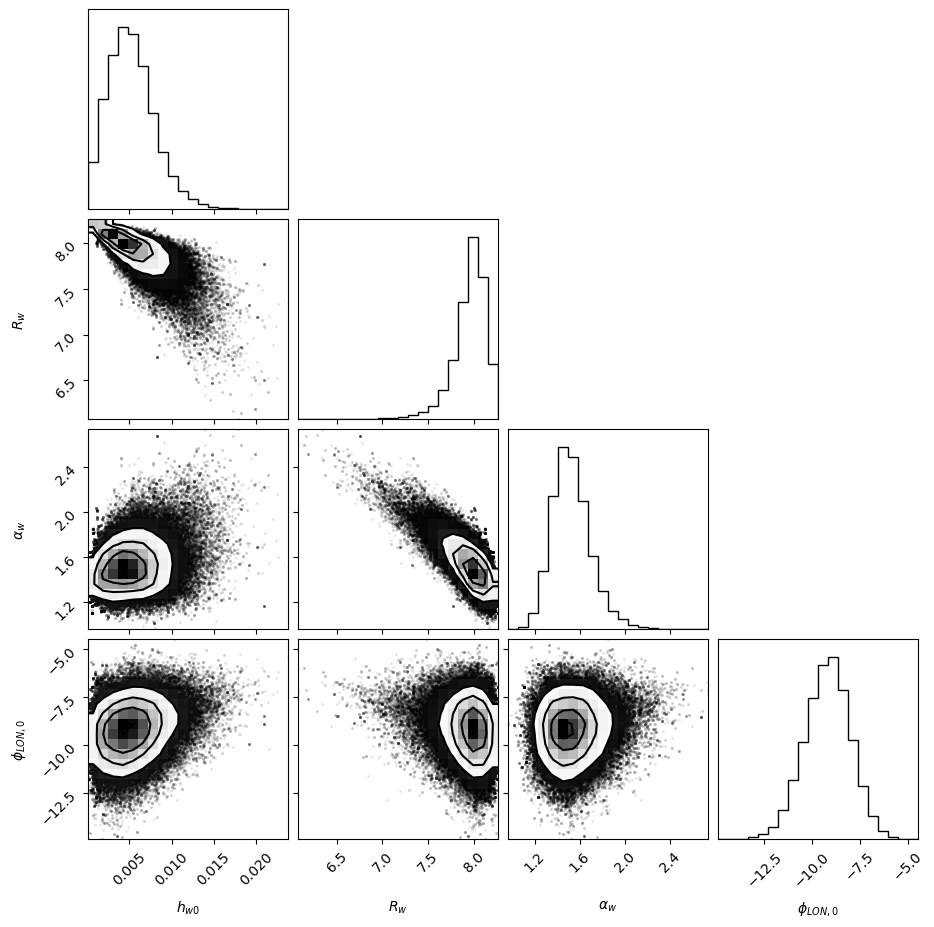

In [98]:
def model_straight(theta, R, phi):
    h_w0, R_w, alpha_w, phiLON0 = theta
    A = A_of_R(R, h_w0, R_w, alpha_w)
    return A * np.sin(phi - np.radians(phiLON0))

def lnlike_straight(theta, R, phi, z, zerr):
    z_model = model_straight(theta, R, phi)
    sigma2 = zerr**2
    return -0.5 * np.sum((z - z_model)**2 / sigma2 + np.log(sigma2))

def lnprior_straight(theta):
    h_w0, R_w, alpha_w, phiLON0 = theta
    if (0.0001 < h_w0 < 2.0 and 3.0 < R_w < R_sun and
        0.1 < alpha_w < 5.0 and -180.0 < phiLON0 < 180.0):
        return 0.0
    return -np.inf

def lnprob_straight(theta, R, phi, z, zerr):
    lp = lnprior_straight(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + lnlike_straight(theta, R, phi, z, zerr)

ndim_s = 4
nwalkers = 100
nsteps = 6000
burnin = 3000

p0_straight = np.array([0.3, 5.5, 1.5, -20.0])
pos_s = [p0_straight + p0_straight * 0.05 * np.random.randn(ndim_s) for _ in range(nwalkers)]

sampler_straight = emcee.EnsembleSampler(
    nwalkers, ndim_s, lnprob_straight,
    args=(R_all, phi_eloisa_rad_all, z0_all, z0_err_all)
)
sampler_straight.run_mcmc(pos_s, nsteps, progress=True)

samples_straight = sampler_straight.chain[:, burnin:, :].reshape((-1, ndim_s))

labels_s = [r"$h_{w0}$", r"$R_w$", r"$\alpha_w$", r"$\phi_{LON,0}$"]
med_s = np.median(samples_straight, axis=0)
for lbl, v in zip(labels_s, med_s):
    print(f"{lbl}: {v:.3f}")

fig = corner.corner(samples_straight, labels=labels_s)
plt.show()

100%|██████████████████████████████████████| 6000/6000 [00:13<00:00, 458.55it/s]


$h_{w0}$: 0.002
$R_w$: 7.900
$\alpha_w$: 2.004
$\phi_{LON,0}$: -16.974
$R_t$: 12.000
$\beta_w$: 6.907


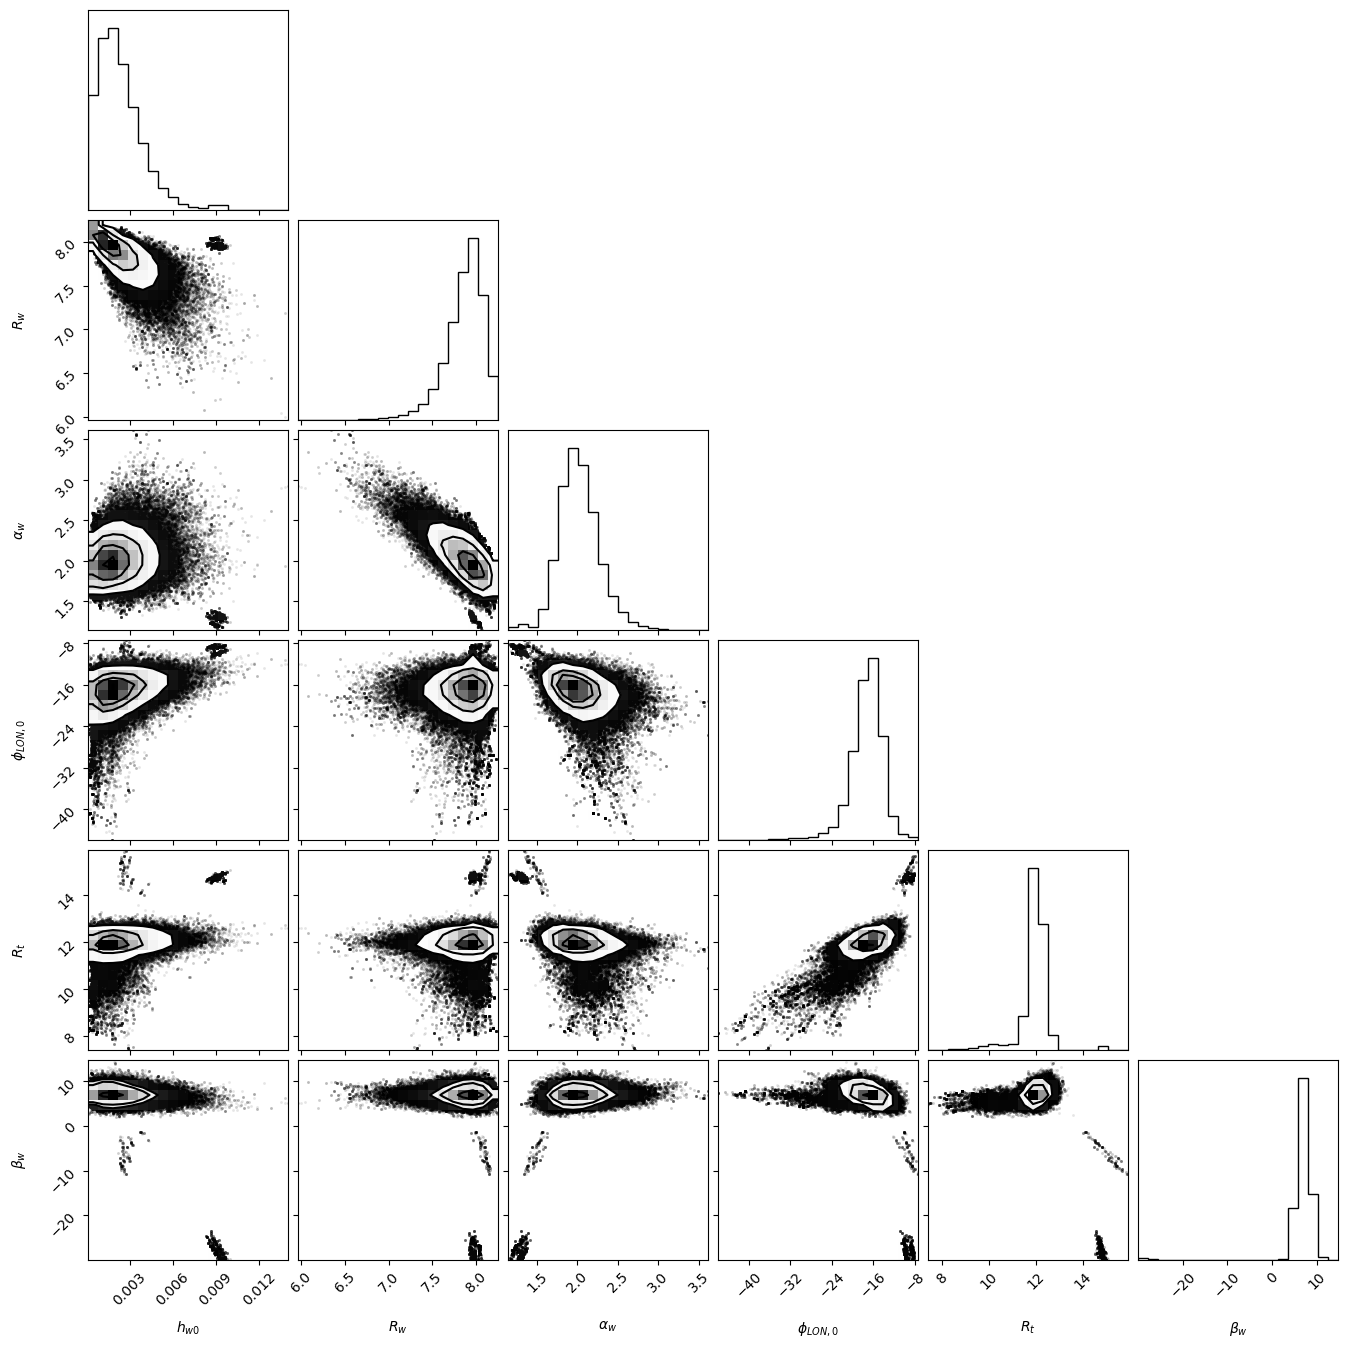

In [99]:
def phiLON_twisted(R, phiLON0, R_t, beta_w):
    return np.where(R < R_t, phiLON0, phiLON0 + beta_w * (R - R_t))

def model_twisted(theta, R, phi):
    h_w0, R_w, alpha_w, phiLON0, R_t, beta_w = theta
    A = A_of_R(R, h_w0, R_w, alpha_w)
    phiLON = phiLON_twisted(R, phiLON0, R_t, beta_w)
    return A * np.sin(phi - np.radians(phiLON))

def lnlike_twisted(theta, R, phi, z, zerr):
    z_model = model_twisted(theta, R, phi)
    sigma2 = zerr**2
    return -0.5 * np.sum((z - z_model)**2 / sigma2 + np.log(sigma2))

def lnprior_twisted(theta):
    h_w0, R_w, alpha_w, phiLON0, R_t, beta_w = theta
    if (0.0001 < h_w0 < 2.0 and 3.0 < R_w < R_sun and
        0.1 < alpha_w < 5.0 and -180.0 < phiLON0 < 180.0 and
        R_w < R_t < 16.0 and -30.0 < beta_w < 30.0):
        return 0.0
    return -np.inf

def lnprob_twisted(theta, R, phi, z, zerr):
    lp = lnprior_twisted(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + lnlike_twisted(theta, R, phi, z, zerr)

ndim_t = 6
p0_twisted = np.array([0.3, 5.5, 1.5, -20.0, 9.0, 0.0])
pos_t = [p0_twisted + np.abs(p0_twisted) * 0.05 * np.random.randn(ndim_t) + 1e-4*np.random.randn(ndim_t)
         for _ in range(nwalkers)]

sampler_twisted = emcee.EnsembleSampler(
    nwalkers, ndim_t, lnprob_twisted,
    args=(R_all, phi_eloisa_rad_all, z0_all, z0_err_all)
)
sampler_twisted.run_mcmc(pos_t, nsteps, progress=True)

samples_twisted = sampler_twisted.chain[:, burnin:, :].reshape((-1, ndim_t))

labels_t = [r"$h_{w0}$", r"$R_w$", r"$\alpha_w$", r"$\phi_{LON,0}$", r"$R_t$", r"$\beta_w$"]
med_t = np.median(samples_twisted, axis=0)
for lbl, v in zip(labels_t, med_t):
    print(f"{lbl}: {v:.3f}")

fig = corner.corner(samples_twisted, labels=labels_t)
plt.show()

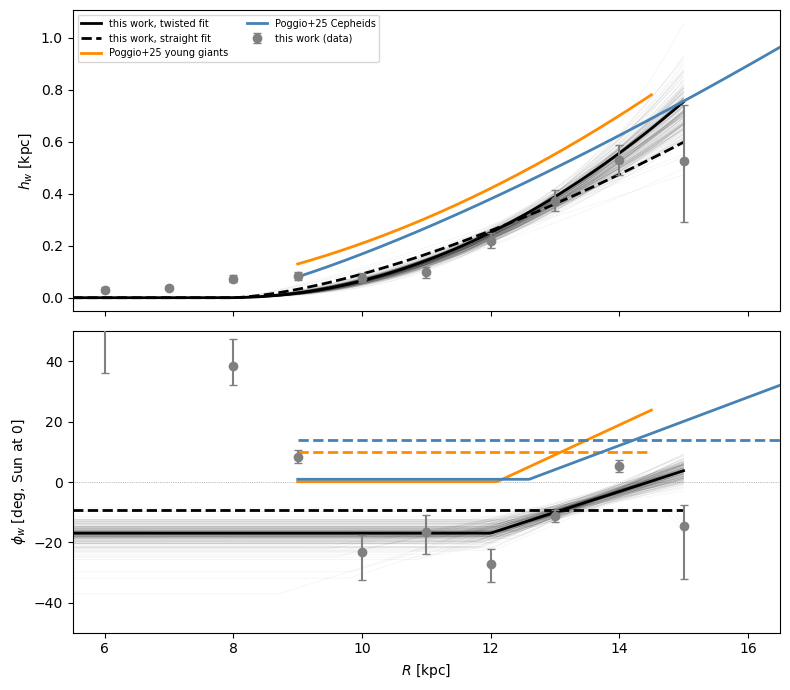

In [100]:
R_grid_yg = np.linspace(9, 14.5, 300)
R_grid_ceph = np.linspace(9, 16.5, 300)
R_grid_mine = np.linspace(R_all.min(), R_all.max(), 300)

hw_yg = h_w_paper(R_grid_yg, yg["R_w"], yg["h_w0"], yg["alpha_w"])
hw_ceph = h_w_paper(R_grid_ceph, ceph["R_w"], ceph["h_w0"], ceph["alpha_w"])

phi_yg_twisted = phiLON_paper(R_grid_yg, yg["phiLON0"], yg["R_t"], yg["beta_w"])
phi_yg_straight = np.full_like(R_grid_yg, yg_straight_phiLON)

phi_ceph_twisted = phiLON_paper(R_grid_ceph, ceph["phiLON0"], ceph["R_t"], ceph["beta_w"])
phi_ceph_straight = np.full_like(R_grid_ceph, ceph_straight_phiLON)

h_w0_s, R_w_s, alpha_w_s, phiLON0_s = med_s
hw_mine_straight = A_of_R(R_grid_mine, h_w0_s, R_w_s, alpha_w_s)
phi_mine_straight = np.full_like(R_grid_mine, phiLON0_s)

h_w0_t, R_w_t, alpha_w_t, phiLON0_t, R_t_t, beta_w_t = med_t
hw_mine_twisted = A_of_R(R_grid_mine, h_w0_t, R_w_t, alpha_w_t)
phi_mine_twisted = phiLON_twisted(R_grid_mine, phiLON0_t, R_t_t, beta_w_t)

R_list = [emcee_results[i]["R_c"] for i in valid_rings]
hw_list = [emcee_results[i]["hw_med"] for i in valid_rings]
hw_err = [[emcee_results[i]["hw_lo"] for i in valid_rings],
          [emcee_results[i]["hw_hi"] for i in valid_rings]]
phiw_list = [emcee_results[i]["phiw_med"] for i in valid_rings]
phiw_err = [[emcee_results[i]["phiw_lo"] for i in valid_rings],
            [emcee_results[i]["phiw_hi"] for i in valid_rings]]

n_sub = 200
np.random.seed(0)
idx_sub = np.random.choice(samples_twisted.shape[0], n_sub, replace=False)

hw_sub = np.zeros((n_sub, R_grid_mine.size))
phi_sub = np.zeros((n_sub, R_grid_mine.size))
for j, i in enumerate(idx_sub):
    h_w0_d, R_w_d, alpha_w_d, phiLON0_d, R_t_d, beta_w_d = samples_twisted[i]
    hw_sub[j] = A_of_R(R_grid_mine, h_w0_d, R_w_d, alpha_w_d)
    phi_sub[j] = phiLON_twisted(R_grid_mine, phiLON0_d, R_t_d, beta_w_d)

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

for j in range(n_sub):
    axes[0].plot(R_grid_mine, hw_sub[j], color='black', lw=0.5, alpha=0.05, zorder=1)
axes[0].plot(R_grid_mine, hw_mine_twisted, color='black', lw=2, ls='-', zorder=3, label='this work, twisted fit')
axes[0].plot(R_grid_mine, hw_mine_straight, color='black', lw=2, ls='--', zorder=3, label='this work, straight fit')
axes[0].plot(R_grid_yg, hw_yg, color='darkorange', lw=2, zorder=3, label='Poggio+25 young giants')
axes[0].plot(R_grid_ceph, hw_ceph, color='steelblue', lw=2, zorder=3, label='Poggio+25 Cepheids')
axes[0].errorbar(R_list, hw_list, yerr=hw_err, fmt='o', color='grey', capsize=3, zorder=4, label='this work (data)')
axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[0].legend(fontsize=7, ncol=2)

for j in range(n_sub):
    axes[1].plot(R_grid_mine, phi_sub[j], color='black', lw=0.5, alpha=0.05, zorder=1)
axes[1].plot(R_grid_mine, phi_mine_twisted, color='black', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_mine, phi_mine_straight, color='black', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_yg, phi_yg_twisted, color='darkorange', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_yg, phi_yg_straight, color='darkorange', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_ceph, phi_ceph_twisted, color='steelblue', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_ceph, phi_ceph_straight, color='steelblue', lw=2, ls='--', zorder=3)
axes[1].errorbar(R_list, phiw_list, yerr=phiw_err, fmt='o', color='grey', capsize=3, zorder=4)
axes[1].axhline(0, color='gray', lw=0.5, ls=':')
axes[1].set_ylabel(r"$\phi_w$ [deg, Sun at 0]")
axes[1].set_xlabel(r"$R$ [kpc]")
axes[1].set_xlim(5.5, 16.5)
axes[1].set_ylim(-50, 50)

plt.tight_layout()
plt.show()

In [217]:
import numpy as np

def summarize_samples(samples, param_names, angle_params=()):
    """
    samples: 2D array (n_samples, n_params), e.g. from sampler.get_chain(discard=burnin, thin=thin, flat=True)
    param_names: list of parameter names, in the same column order as samples
    angle_params: names (subset of param_names) that are in radians and should be reported in degrees
    """
    summary = {}
    for i, name in enumerate(param_names):
        vals = samples[:, i]
        if name in angle_params:
            vals = np.degrees(vals)
        med = np.median(vals)
        lo, hi = np.percentile(vals, [16, 84])
        summary[name] = {"median": med, "lo": lo, "hi": hi,
                          "err_minus": med - lo, "err_plus": hi - med}
        print(f"{name:10s} = {med:8.3f}  (+{hi-med:.3f} / -{med-lo:.3f})   "
              f"[16th={lo:.3f}, 84th={hi:.3f}]")
    return summary

# --- straight-LON model ---
flat_straight = sampler_straight.get_chain(discard=1000, thin=10, flat=True)
print("straight-LON:")
summary_straight = summarize_samples(
    flat_straight,
    param_names=["h_w0", "R_w", "alpha_w", "phiLON0"],
    angle_params=[],   # already in degrees, no conversion needed
)

print()

flat_twisted = sampler_twisted.get_chain(discard=1000, thin=10, flat=True)
print("twisted-LON:")
summary_twisted = summarize_samples(
    flat_twisted,
    param_names=["h_w0", "R_w", "alpha_w", "phiLON0", "R_t", "beta_w"],
    angle_params=[],   # already in degrees, no conversion needed
)

straight-LON:
h_w0       =    0.005  (+0.003 / -0.002)   [16th=0.003, 84th=0.008]
R_w        =    7.981  (+0.134 / -0.182)   [16th=7.799, 84th=8.115]
alpha_w    =    1.510  (+0.177 / -0.147)   [16th=1.362, 84th=1.687]
phiLON0    =   -9.179  (+1.144 / -1.211)   [16th=-10.390, 84th=-8.034]

twisted-LON:
h_w0       =    0.002  (+0.002 / -0.001)   [16th=0.001, 84th=0.004]
R_w        =    7.899  (+0.161 / -0.236)   [16th=7.664, 84th=8.060]
alpha_w    =    2.007  (+0.250 / -0.213)   [16th=1.793, 84th=2.257]
phiLON0    =  -17.003  (+2.429 / -2.816)   [16th=-19.819, 84th=-14.574]
R_t        =   11.998  (+0.269 / -0.329)   [16th=11.669, 84th=12.268]
beta_w     =    6.906  (+1.361 / -1.311)   [16th=5.595, 84th=8.266]


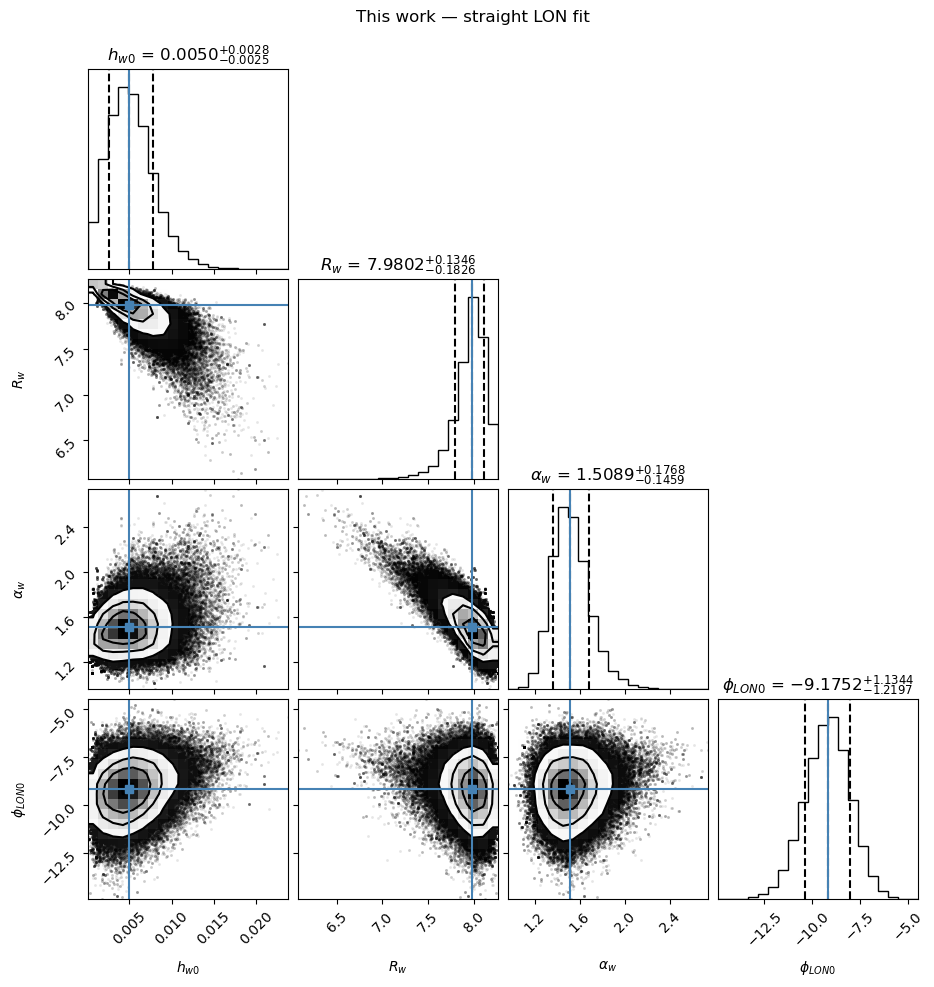

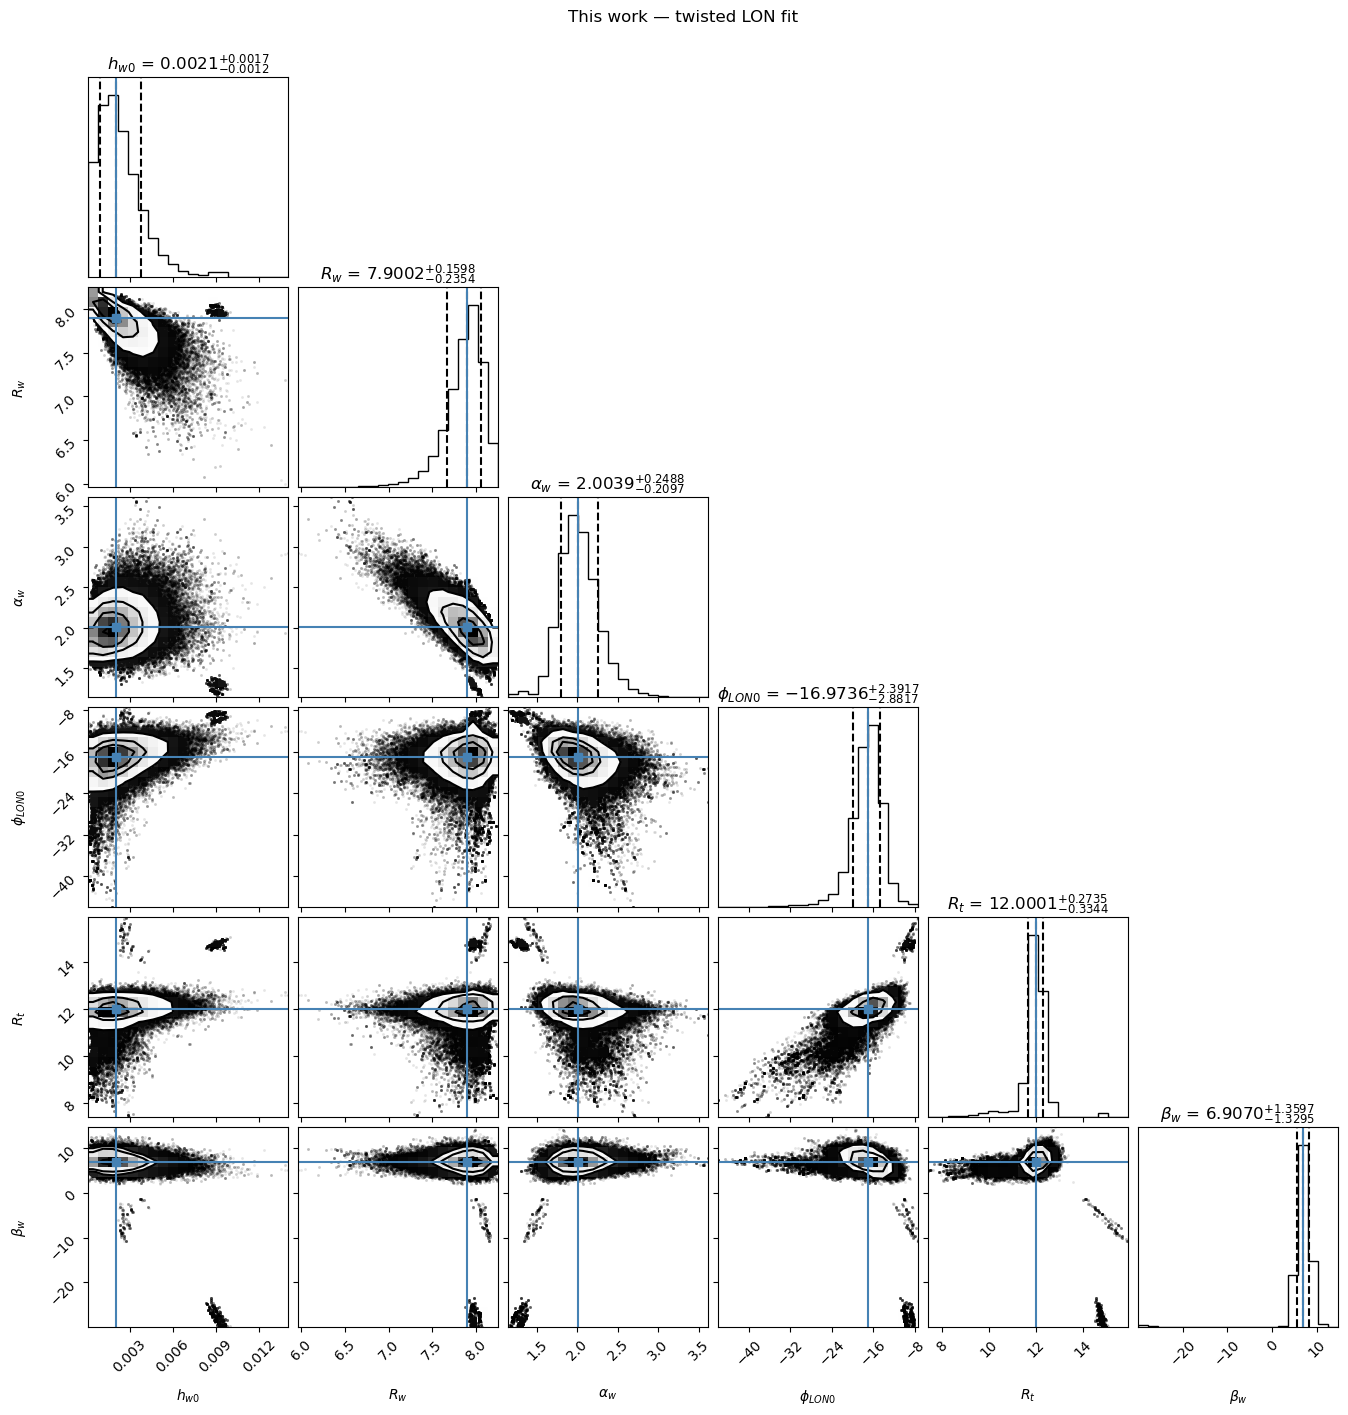

In [152]:
import corner

labels_s_plain = [r"$h_{w0}$", r"$R_w$", r"$\alpha_w$", r"$\phi_{LON0}$"]
labels_t_plain = [r"$h_{w0}$", r"$R_w$", r"$\alpha_w$", r"$\phi_{LON0}$", r"$R_t$", r"$\beta_w$"]

# corner plot for the straight LON fit
fig_s = corner.corner(
    samples_straight,
    labels=labels_s_plain,
    truths=med_s,
    show_titles=True,
    title_fmt=".4f",
    quantiles=[0.16, 0.5, 0.84],
)
fig_s.suptitle("This work — straight LON fit", y=1.02)
plt.show()

# corner plot for the twisted LON fit
fig_t = corner.corner(
    samples_twisted,
    labels=labels_t_plain,
    truths=med_t,
    show_titles=True,
    title_fmt=".4f",
    quantiles=[0.16, 0.5, 0.84],
)
fig_t.suptitle("This work — twisted LON fit", y=1.02)
plt.show()

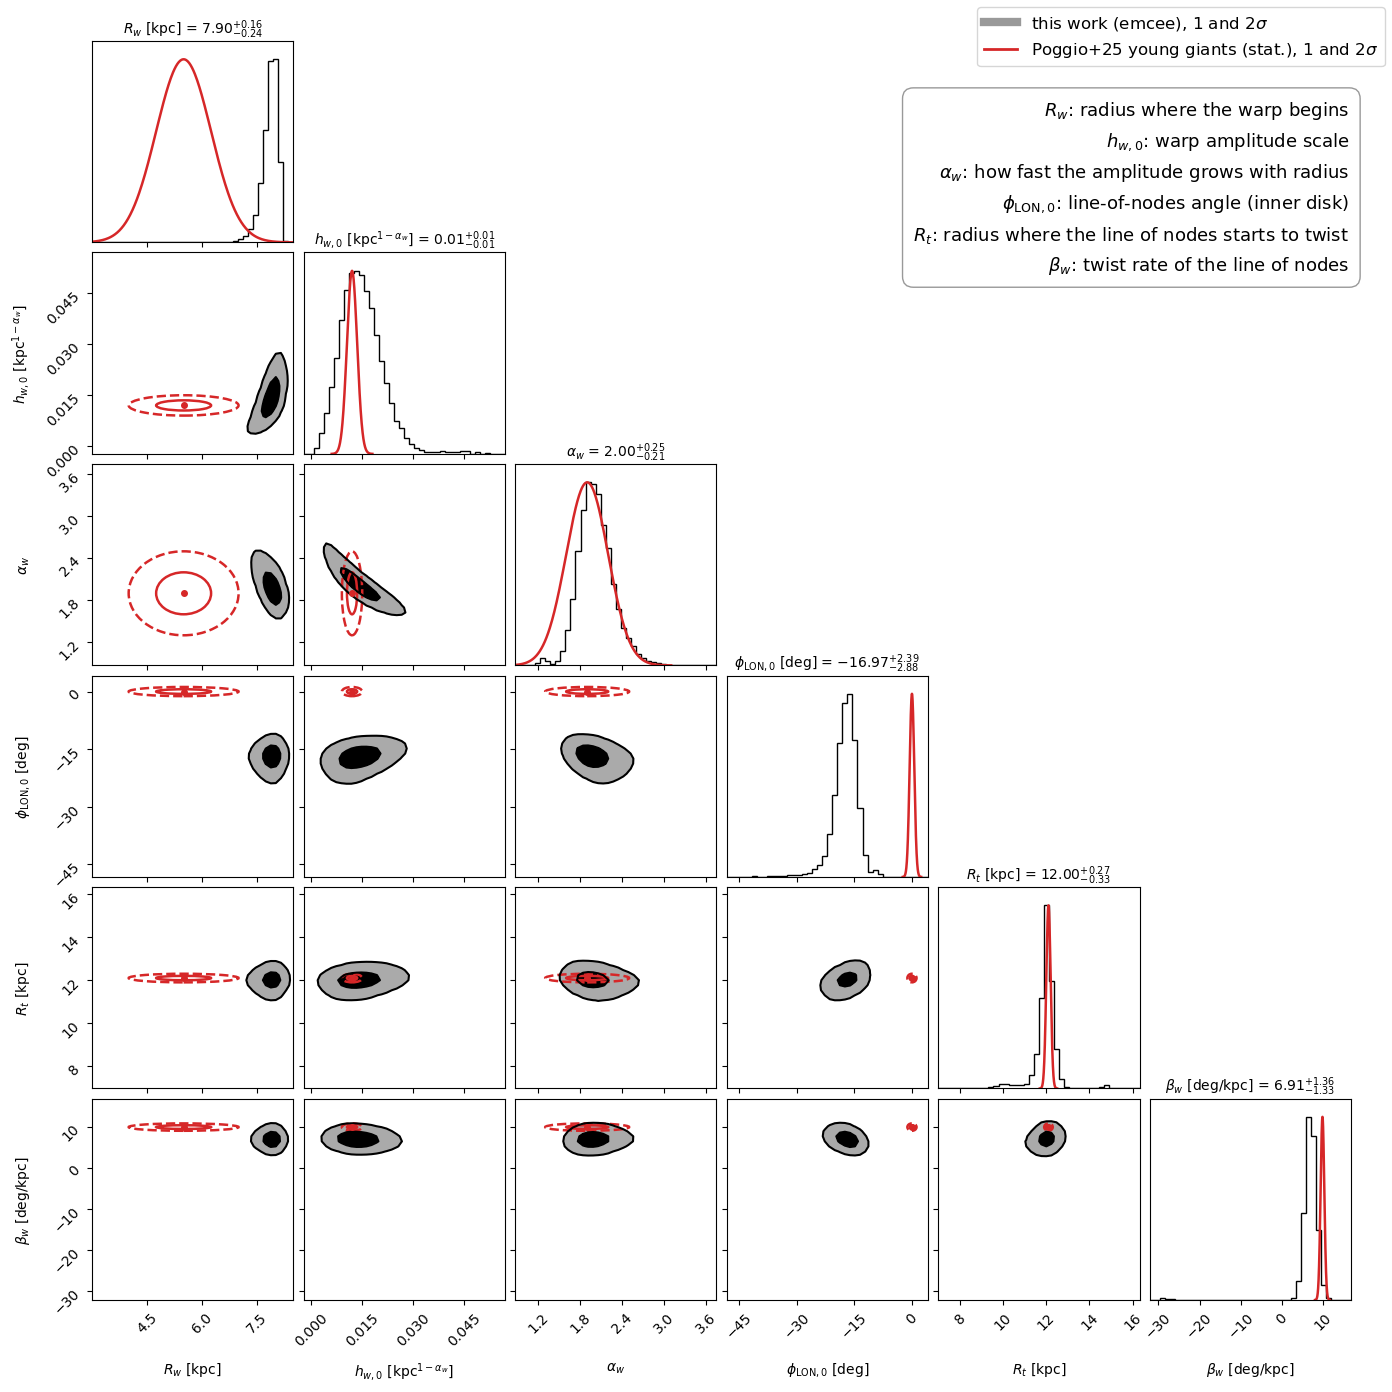

In [244]:
import numpy as np
import corner
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from matplotlib.lines import Line2D

# ------------------------------------------------------------------
# Settings
# ------------------------------------------------------------------
UNCERTAINTY = "stat"            # "stat" = Poggio statistical only, "total" = stat and sys in quadrature
R_SUN = 8.275                   # matches the emcee model's normalization
EMCEE_SAMPLES = samples_twisted # (n, 6) flattened chain; or samples_twisted_broad

params = ["R_w", "h_w0", "alpha_w", "phi_LON0", "R_t", "beta_w"]
labels = {
    "R_w":      r"$R_w$ [kpc]",
    "h_w0":     r"$h_{w,0}$ [kpc$^{1-\alpha_w}$]",
    "alpha_w":  r"$\alpha_w$",
    "phi_LON0": r"$\phi_{\rm LON,0}$ [deg]",
    "R_t":      r"$R_t$ [kpc]",
    "beta_w":   r"$\beta_w$ [deg/kpc]",
}

# ------------------------------------------------------------------
# Your emcee chain -> dict, converting h_w0 to Poggio's amplitude convention
# emcee column order: h_w0, R_w, alpha_w, phiLON0, R_t, beta_w
# ------------------------------------------------------------------
h_e, R_w_e, alpha_e, phi0_e, R_t_e, beta_e = EMCEE_SAMPLES.T
emcee_dict = {
    "R_w":      R_w_e,
    "h_w0":     h_e / (R_SUN - R_w_e) ** alpha_e,   # converted to h_w0 (R - R_w)^alpha form
    "alpha_w":  alpha_e,
    "phi_LON0": phi0_e,
    "R_t":      R_t_e,
    "beta_w":   beta_e,
}
chain = np.column_stack([emcee_dict[p] for p in params])

# ------------------------------------------------------------------
# Poggio+25 Table 1 (young giants): best, stat(+, -), sys(+, -)
# ------------------------------------------------------------------
POGGIO_TABLE = {
    "R_w":      (5.5,   (0.8, 0.7),     (1.3, 0.8)),
    "h_w0":     (0.012, (0.002, 0.001), (0.006, 0.001)),
    "alpha_w":  (1.9,   (0.3, 0.3),     (0.5, 0.6)),
    "phi_LON0": (0.1,   (0.6, 0.6),     (1.1, 1.2)),
    "R_t":      (12.1,  (0.1, 0.1),     (0.1, 0.1)),
    "beta_w":   (9.9,   (0.5, 0.4),     (0.4, 0.2)),
}

def poggio_sigma(name):
    _, stat, sys_ = POGGIO_TABLE[name]
    s_stat = 0.5 * (stat[0] + stat[1])
    s_sys  = 0.5 * (sys_[0] + sys_[1])
    return s_stat if UNCERTAINTY == "stat" else np.hypot(s_stat, s_sys)

mu  = np.array([POGGIO_TABLE[p][0] for p in params])
sig = np.array([poggio_sigma(p) for p in params])

# ------------------------------------------------------------------
# Contour plot
# ------------------------------------------------------------------
rng = []
for k in range(len(params)):
    lo = min(chain[:, k].min(), mu[k] - 3 * sig[k])
    hi = max(chain[:, k].max(), mu[k] + 3 * sig[k])
    pad = 0.05 * (hi - lo)
    rng.append((lo - pad, hi + pad))

levels = (1 - np.exp(-0.5), 1 - np.exp(-2.0))   # 1 and 2 sigma for a 2D Gaussian

fig = corner.corner(
    chain, labels=[labels[p] for p in params], range=rng, levels=levels,
    color="k", fill_contours=True, plot_datapoints=False,
    smooth=1.0, bins=40, hist_kwargs={"density": True},
    show_titles=True, title_kwargs={"fontsize": 10},
)
fig.set_size_inches(14, 14)

n = len(params)
axes = np.array(fig.axes).reshape(n, n)

for i in range(n):
    for j in range(i):
        ax = axes[i, j]
        for k, ls in [(1, "-"), (2, "--")]:
            ax.add_patch(Ellipse((mu[j], mu[i]), 2 * k * sig[j], 2 * k * sig[i],
                                 fill=False, ec="C3", lw=1.8, ls=ls))
        ax.plot(mu[j], mu[i], "o", color="C3", ms=4)

    ax = axes[i, i]
    peak = np.histogram(chain[:, i], bins=40, range=rng[i], density=True)[0].max()
    x = np.linspace(mu[i] - 4 * sig[i], mu[i] + 4 * sig[i], 300)
    ax.plot(x, peak * np.exp(-0.5 * ((x - mu[i]) / sig[i]) ** 2), color="C3", lw=1.8)

unc_label = "stat." if UNCERTAINTY == "stat" else "stat. + sys."
fig.legend(
    handles=[
        Line2D([], [], color="k", lw=6, alpha=0.4, label=r"this work (emcee), 1 and 2$\sigma$"),
        Line2D([], [], color="C3", lw=2, label=f"Poggio+25 young giants ({unc_label}), 1 and 2$\\sigma$"),
    ],
    loc="upper right", fontsize=12,
)

legend_lines = [
    r"$R_w$: radius where the warp begins",
    r"$h_{w,0}$: warp amplitude scale",
    r"$\alpha_w$: how fast the amplitude grows with radius",
    r"$\phi_{\rm LON,0}$: line-of-nodes angle (inner disk)",
    r"$R_t$: radius where the line of nodes starts to twist",
    r"$\beta_w$: twist rate of the line of nodes",
]
fig.text(0.97, 0.93, "\n".join(legend_lines), ha="right", va="top", fontsize=13,
         linespacing=1.6,
         bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="0.6"))
plt.show()

In [146]:
labels_s_plain = ["h_w0", "R_w", "alpha_w", "phiLON0"]
labels_t_plain = ["h_w0", "R_w", "alpha_w", "phiLON0", "R_t", "beta_w"]

def print_params(samples, labels, title):
    print("This work")
    print(f"--- {title} ---")
    p16, p50, p84 = np.percentile(samples, [16, 50, 84], axis=0)
    for lbl, lo, med, hi in zip(labels, p16, p50, p84):
        print(f"{lbl:10s} = {med:8.4f}  (+{hi-med:.4f} / -{med-lo:.4f})")
    print()

print_params(samples_straight, labels_s_plain, "Straight LON fit")
print_params(samples_twisted, labels_t_plain, "Twisted LON fit")

This work
--- Straight LON fit ---
h_w0       =   0.0050  (+0.0028 / -0.0025)
R_w        =   7.9802  (+0.1346 / -0.1826)
alpha_w    =   1.5089  (+0.1768 / -0.1459)
phiLON0    =  -9.1752  (+1.1344 / -1.2197)

This work
--- Twisted LON fit ---
h_w0       =   0.0021  (+0.0017 / -0.0012)
R_w        =   7.9002  (+0.1598 / -0.2354)
alpha_w    =   2.0039  (+0.2488 / -0.2097)
phiLON0    = -16.9736  (+2.3917 / -2.8817)
R_t        =  12.0001  (+0.2735 / -0.3344)
beta_w     =   6.9070  (+1.3597 / -1.3295)



In [151]:
labels_s_plain = ["h_w0", "R_w", "alpha_w", "phiLON0"]
labels_t_plain = ["h_w0", "R_w", "alpha_w", "phiLON0", "R_t", "beta_w"]
print("This work:")
def print_params(samples, labels, title):
    print(f"--- {title} ---")
    p50 = np.percentile(samples, 50, axis=0)
    for lbl, med in zip(labels, p50):
        print(f"{lbl:10s} = {med:8.4f}")
    print()

print_params(samples_straight, labels_s_plain, "Straight LON fit")
print_params(samples_twisted, labels_t_plain, "Twisted LON fit")

This work:
--- Straight LON fit ---
h_w0       =   0.0050
R_w        =   7.9802
alpha_w    =   1.5089
phiLON0    =  -9.1752

--- Twisted LON fit ---
h_w0       =   0.0021
R_w        =   7.9002
alpha_w    =   2.0039
phiLON0    = -16.9736
R_t        =  12.0001
beta_w     =   6.9070



In [144]:
yg_params = {
    "h_w0":     0.012,
    "R_w":      5.5,
    "alpha_w":  1.9,
    "phi_LON0": 0.1,
    "R_t":      12.1,
    "beta_w":   9.9,
}
print(f"Poggio+25 Twisted(YG)")

print(f"{'Parameter':10s} {'Value':>10s}")
print("-" * 22)
for name, val in yg_params.items():
    print(f"{name:10s} {val:>10.3f}")

Poggio+25 Twisted (YG)
Parameter       Value
----------------------
h_w0            0.012
R_w             5.500
alpha_w         1.900
phi_LON0        0.100
R_t            12.100
beta_w          9.900


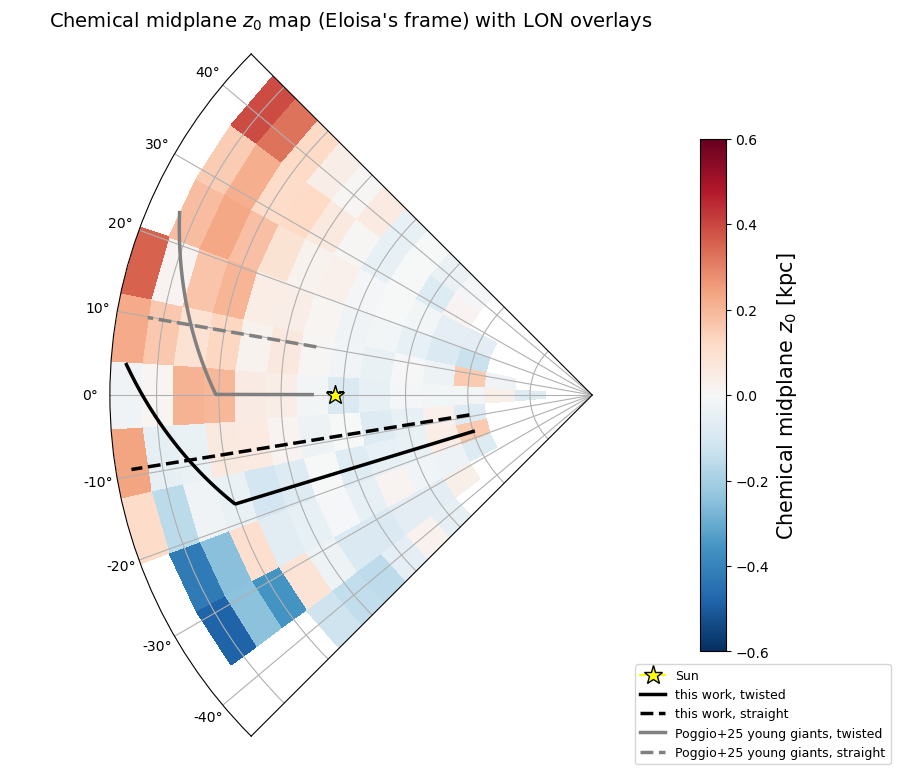

In [156]:
# --- convert bin edges from raw phi_star frame into Eloisa's frame (Sun at 0, +phi = with rotation) ---
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi

theta_edges_deg = np.degrees(theta_edges)
theta_edges_eloisa_deg = np.mod(360.0 - theta_edges_deg, 360) - 180
theta_edges = np.radians(theta_edges_eloisa_deg)

# the conversion reverses direction, so re-sort ascending and flip the data to match
order = np.argsort(theta_edges)
theta_edges = theta_edges[order]
if not np.all(order == np.arange(len(order))):
    z0_med = z0_med[:, ::-1]
    z0_std = z0_std[:, ::-1]
# ---------------------------------------------------------------------------------------

T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
Zmap_med = np.ma.masked_invalid(z0_med)
theta_min, theta_max = theta_edges[0], theta_edges[-1]
theta_sun, R_sun = np.radians(0), 8.275   # Sun at phi=0, +phi = direction of rotation

fig = plt.figure(figsize=(9, 8))
ax1 = plt.subplot(1, 1, 1, projection="polar")
pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Zmap_med, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7).set_label(r"Chemical midplane $z_0$ [kpc]", fontsize=15)
ax1.set_theta_zero_location("W"); ax1.set_theta_direction(-1); ax1.set_rmax(R_edges[-1])
ax1.set_thetamin(np.degrees(theta_min)); ax1.set_thetamax(np.degrees(theta_max))
ax1.set_yticklabels([])
ax1.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14, markeredgecolor="k", zorder=6, label="Sun")

# --- overlay the LON curves (already in Eloisa's frame, deg, Sun at 0) ---
ax1.plot(np.radians(phi_mine_twisted), R_grid_mine, color='black', lw=2.5, ls='-',
          zorder=5, label='this work, twisted')
ax1.plot(np.radians(phi_mine_straight), R_grid_mine, color='black', lw=2.5, ls='--',
          zorder=5, label='this work, straight')
ax1.plot(np.radians(phi_yg_twisted), R_grid_yg, color='grey', lw=2.5, ls='-',
          zorder=5, label='Poggio+25 young giants, twisted')
ax1.plot(np.radians(phi_yg_straight), R_grid_yg, color='grey', lw=2.5, ls='--',
          zorder=5, label='Poggio+25 young giants, straight')

ax1.legend(loc="lower right", fontsize=9, bbox_to_anchor=(1.3, -0.05))
ax1.set_title("Chemical midplane $z_0$ map (Eloisa's frame) with LON overlays", fontsize=14, pad=20)

plt.tight_layout()
plt.show()

## Comparison to Literature

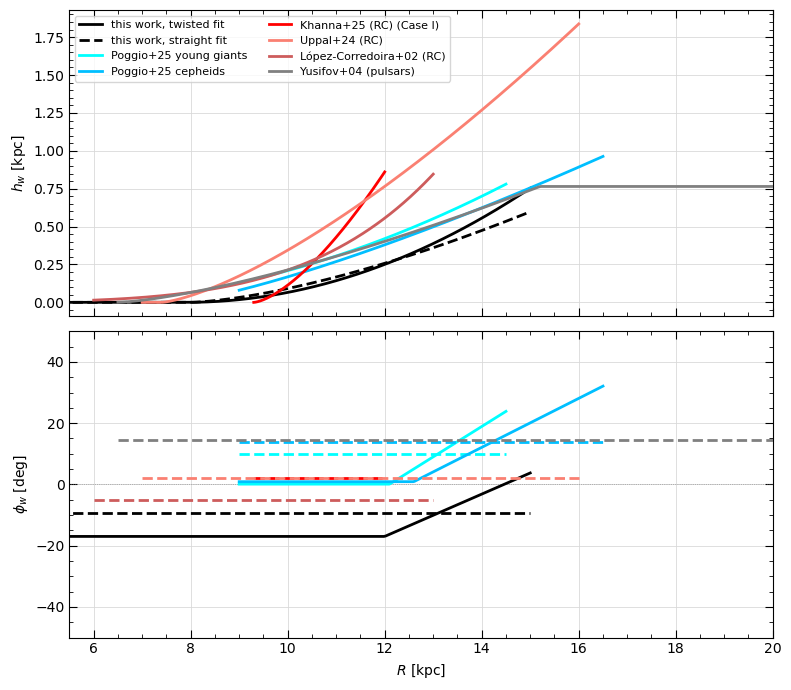

In [228]:
# ---- amplitude + LON functions for each literature source ----

def A_rc_paper(R, h_w0, R_w, alpha_w):
    """Khanna+25 / other RC-paper amplitude: h_w0 * (R-R_w)^alpha_w, NOT normalized like A_of_R."""
    return h_w0 * np.clip(R - R_w, 0, None)**alpha_w

def A_uppal(R, C_w=0.0057, R_w=7.4, eps_w=1.40):
    """Uppal+24: R in pc internally, output converted pc -> kpc."""
    R_pc, Rw_pc = R*1000.0, R_w*1000.0
    return C_w * np.clip(R_pc - Rw_pc, 0, None)**eps_w / 1000.0

def A_lopez(R, C_w=1.2e-3, exp=5.25):
    """Lopez-Corredoira+02: R in kpc directly, output in pc -> convert to kpc."""
    return C_w * np.clip(R, 0, None)**exp / 1000.0

def A_yusifov(R, C_w=37.0, R_w=6.5, b_w=1.4, R_WS=15.2):
    """Yusifov 2004 (pulsars): saturates beyond R_WS, output pc -> kpc. Small +15pc offset dropped (negligible, Sun-height nuisance term)."""
    R_eff = np.clip(np.minimum(R, R_WS) - R_w, 0, None)
    return (C_w * R_eff**b_w) / 1000.0

# ---- parameter choices ----
khanna = dict(h_w0=0.194, R_w=9.30, alpha_w=1.5, phiLON0=2.0)   # Case I

uppal   = dict(C_w=0.0057, R_w=7.4,  eps_w=1.40, phiLON0=2.03)
lopez   = dict(C_w=1.2e-3, exp=5.25,             phiLON0=-5.0)
yusifov = dict(C_w=37.0, R_w=6.5, b_w=1.4, R_WS=15.2, phiLON0=14.5)  # sign-flipped, see caveat above

# ---- radial grids (matched to each paper's stated valid range) ----
R_grid_rc1   = np.linspace(9.30, 12.0, 300)   # RC-paper amplitude only reliable to ~R~12 kpc
R_grid_uppal = np.linspace(7.0, 16.0, 300)
R_grid_lopez = np.linspace(6.0, 13.0, 300)
R_grid_yus   = np.linspace(6.5, 20.0, 300)

hw_rc1   = A_rc_paper(R_grid_rc1, khanna["h_w0"], khanna["R_w"], khanna["alpha_w"])
hw_uppal = A_uppal(R_grid_uppal, uppal["C_w"], uppal["R_w"], uppal["eps_w"])
hw_lopez = A_lopez(R_grid_lopez, lopez["C_w"], lopez["exp"])
hw_yus   = A_yusifov(R_grid_yus, yusifov["C_w"], yusifov["R_w"], yusifov["b_w"], yusifov["R_WS"])

phi_rc1   = np.full_like(R_grid_rc1, khanna["phiLON0"])
phi_uppal = np.full_like(R_grid_uppal, uppal["phiLON0"])
phi_lopez = np.full_like(R_grid_lopez, lopez["phiLON0"])
phi_yus   = np.full_like(R_grid_yus, yusifov["phiLON0"])

from matplotlib.ticker import AutoMinorLocator

# ---- figure ----
fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

axes[0].plot(R_grid_mine, hw_mine_twisted, color='black', lw=2, ls='-', zorder=3, label='this work, twisted fit')
axes[0].plot(R_grid_mine, hw_mine_straight, color='black', lw=2, ls='--', zorder=3, label='this work, straight fit')
axes[0].plot(R_grid_yg, hw_yg, color='cyan', lw=2, zorder=3, label='Poggio+25 young giants')
axes[0].plot(R_grid_ceph, hw_ceph, color='deepskyblue', lw=2, zorder=3, label='Poggio+25 cepheids')
axes[0].plot(R_grid_rc1, hw_rc1, color='red', lw=2, zorder=3, label='Khanna+25 (RC) (Case I)')
axes[0].plot(R_grid_uppal, hw_uppal, color='salmon', lw=2, zorder=3, label='Uppal+24 (RC)')
axes[0].plot(R_grid_lopez, hw_lopez, color='indianred', lw=2, zorder=3, label='López-Corredoira+02 (RC)')
axes[0].plot(R_grid_yus, hw_yus, color='gray', lw=2, zorder=3, label='Yusifov+04 (pulsars)')
axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[0].legend(fontsize=8, ncol=2)

axes[1].plot(R_grid_mine, phi_mine_twisted, color='black', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_mine, phi_mine_straight, color='black', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_yg, phi_yg_twisted, color='cyan', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_yg, phi_yg_straight, color='cyan', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_ceph, phi_ceph_twisted, color='deepskyblue', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_ceph, phi_ceph_straight, color='deepskyblue', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_rc1, phi_rc1, color='red', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_uppal, phi_uppal, color='salmon', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_lopez, phi_lopez, color='indianred', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_yus, phi_yus, color='gray', lw=2, ls='--', zorder=3)
axes[1].axhline(0, color='gray', lw=0.5, ls=':')
axes[1].set_ylabel(r"$\phi_w$ [deg]")
axes[1].set_xlabel(r"$R$ [kpc]")
axes[1].set_xlim(5.5, 20)
axes[1].set_ylim(-50, 50)

# ---- major/minor ticks + gridlines on both panels ----
for ax in axes:
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.yaxis.set_minor_locator(AutoMinorLocator())
    ax.tick_params(which='major', length=6, direction='in', top=True, right=True)
    ax.tick_params(which='minor', length=3, direction='in', top=True, right=True)
    ax.grid(which='major', color='0.85', linestyle='-', linewidth=0.6, zorder=0)
    #ax.grid(which='minor', color='0.92', linestyle='-', linewidth=0.4, zorder=0)

plt.tight_layout()
fig.savefig("lon_amplitude_comparison.pdf", bbox_inches="tight")
plt.show()

In [135]:
sources = {
    "Khanna+25 (RC, Case I)":       khanna["phiLON0"],
    "Uppal+24 (RC)":                uppal["phiLON0"],
    "López-Corredoira+02 (RC)":     lopez["phiLON0"],
    "Yusifov+04 (pulsars)":         yusifov["phiLON0"],
    "This work, straight fit":      phi_mine_straight,
    "This work, twisted fit":       phi_mine_twisted,
    "Poggio+25 young giants, straight": phi_yg_straight,
    "Poggio+25 young giants, twisted":  phi_yg_twisted,
    "Poggio+25 Cepheids, straight":     phi_ceph_straight,
    "Poggio+25 Cepheids, twisted":      phi_ceph_twisted,
}

print(f"{'Source':32s}  phi_LON")
print("-" * 41)
for name, phi in sources.items():
    phi_arr = np.atleast_1d(phi)
    if np.ptp(phi_arr) < 1e-8:   # effectively constant (straight-fit case)
        print(f"{name:32s}  {phi_arr[0]:+7.2f}")
    else:                        # varies with R (twisted-fit case)
        print(f"{name:32s}  {phi_arr.min():+7.2f}")

Source                            phi_LON
-----------------------------------------
Khanna+25 (RC, Case I)              -2.00
Uppal+24 (RC)                       +2.03
López-Corredoira+02 (RC)            -5.00
Yusifov+04 (pulsars)               +14.50
This work, straight fit             -9.18
This work, twisted fit             -16.97
Poggio+25 young giants, straight    +9.90
Poggio+25 young giants, twisted     +0.10
Poggio+25 Cepheids, straight       +14.00
Poggio+25 Cepheids, twisted         +0.90


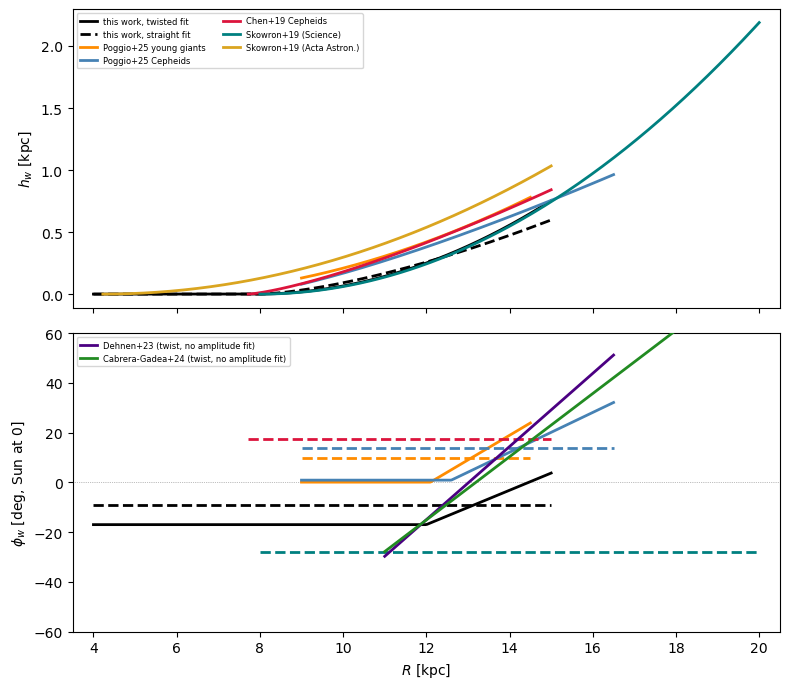

In [115]:
# ---- amplitude functions (straight-LON Cepheid papers) ----

def A_chen(R, a=0.060, R_w=7.72, b=1.33):
    return a * np.clip(R - R_w, 0, None)**b

def A_skowron_sci(R, z1=0.0152, Rd=8.0):
    return z1 * np.clip(R - Rd, 0, None)**2

def A_skowron_acta(R, z1=0.0089, Rd=4.2258):
    return z1 * np.clip(R - Rd, 0, None)**2

# ---- parameters ----
chen        = dict(a=0.060, R_w=7.72, b=1.33, phiLON0=17.5)
skow_sci    = dict(z1=0.0152, Rd=8.0,          phiLON0=-28.0)
skow_acta   = dict(z1=0.0089, Rd=4.2258,       phiLON0=158.3)  # m=1 (dominant) mode only

# Dehnen+23: no sign flip, use their own anchor/slope directly (already Sun=0, positive/leading slope)
def phi_dehnen(R, R0=12.0, phi0=-15.0, slope=14.7):
    return phi0 + slope*(R - R0)

# Cabrera-Gadea+24: correct conversion needs BOTH the 180 deg zero-point shift AND
# a sign flip for the rotation-sense difference (previously only did the shift)
def phi_cabrera_gadea(R, slope=-12.7, intercept=347.5):
    phi_theirs = slope*R + intercept
    return 180.0 - phi_theirs
    
# ---- radial grids (matched to each paper's valid range) ----
R_grid_chen      = np.linspace(chen["R_w"], 15.0, 300)
R_grid_skow_sci  = np.linspace(skow_sci["Rd"], 20.0, 300)
R_grid_skow_acta = np.linspace(skow_acta["Rd"], 15.0, 300)
R_grid_dehnen    = np.linspace(11.0, 16.5, 300)
R_grid_cg        = np.linspace(11.0, 18.0, 300)

hw_chen      = A_chen(R_grid_chen, chen["a"], chen["R_w"], chen["b"])
hw_skow_sci  = A_skowron_sci(R_grid_skow_sci, skow_sci["z1"], skow_sci["Rd"])
hw_skow_acta = A_skowron_acta(R_grid_skow_acta, skow_acta["z1"], skow_acta["Rd"])

phi_chen_line      = np.full_like(R_grid_chen, chen["phiLON0"])
phi_skow_sci_line  = np.full_like(R_grid_skow_sci, skow_sci["phiLON0"])
phi_skow_acta_line = np.full_like(R_grid_skow_acta, skow_acta["phiLON0"])
phi_dehnen_line    = phi_dehnen(R_grid_dehnen)
phi_cg_line        = phi_cabrera_gadea(R_grid_cg)

# ---- figure ----
fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

axes[0].plot(R_grid_mine, hw_mine_twisted, color='black', lw=2, ls='-', zorder=3, label='this work, twisted fit')
axes[0].plot(R_grid_mine, hw_mine_straight, color='black', lw=2, ls='--', zorder=3, label='this work, straight fit')
axes[0].plot(R_grid_yg, hw_yg, color='darkorange', lw=2, zorder=3, label='Poggio+25 young giants')
axes[0].plot(R_grid_ceph, hw_ceph, color='steelblue', lw=2, zorder=3, label='Poggio+25 Cepheids')
axes[0].plot(R_grid_chen, hw_chen, color='crimson', lw=2, zorder=3, label='Chen+19 Cepheids')
axes[0].plot(R_grid_skow_sci, hw_skow_sci, color='teal', lw=2, zorder=3, label='Skowron+19 (Science)')
axes[0].plot(R_grid_skow_acta, hw_skow_acta, color='goldenrod', lw=2, zorder=3, label='Skowron+19 (Acta Astron.)')
#axes[0].errorbar(R_list, hw_list, yerr=hw_err, fmt='o', color='grey', capsize=3, zorder=4, label='this work (data)')
axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[0].legend(fontsize=6, ncol=2)

axes[1].plot(R_grid_mine, phi_mine_twisted, color='black', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_mine, phi_mine_straight, color='black', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_yg, phi_yg_twisted, color='darkorange', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_yg, phi_yg_straight, color='darkorange', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_ceph, phi_ceph_twisted, color='steelblue', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_ceph, phi_ceph_straight, color='steelblue', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_chen, phi_chen_line, color='crimson', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_skow_sci, phi_skow_sci_line, color='teal', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_skow_acta, phi_skow_acta_line, color='goldenrod', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_dehnen, phi_dehnen_line, color='indigo', lw=2, ls='-', zorder=3, label='Dehnen+23 (twist, no amplitude fit)')
axes[1].plot(R_grid_cg, phi_cg_line, color='forestgreen', lw=2, ls='-', zorder=3, label='Cabrera-Gadea+24 (twist, no amplitude fit)')
#axes[1].errorbar(R_list, phiw_list, yerr=phiw_err, fmt='o', color='grey', capsize=3, zorder=4)
axes[1].axhline(0, color='gray', lw=0.5, ls=':')
axes[1].set_ylabel(r"$\phi_w$ [deg, Sun at 0]")
axes[1].set_xlabel(r"$R$ [kpc]")
axes[1].set_xlim(3.5, 20.5)
axes[1].set_ylim(-60, 60)

axes[1].legend(fontsize=6, loc='upper left')
plt.tight_layout()
plt.show()

In [230]:
with open(RESULTS_PATH, "rb") as f:
    saved_map = pickle.load(f)

n_stars_map = saved_map["n_stars"]   # 2D array, (n_R, n_seg)
ok_grid_map = saved_map["ok_grid"]

n_used_in_successful_fits = int(np.sum(n_stars_map[ok_grid_map]))
print(f"stars in (R,phi) cells where the sech^2 fit actually converged: {n_used_in_successful_fits:,}")
print(f"({ok_grid_map.sum()}/{ok_grid_map.size} cells had a successful fit)")

stars in (R,phi) cells where the sech^2 fit actually converged: 369,812
(121/165 cells had a successful fit)


/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/2600209016.py:10: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/2600209016.py:11: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64311/2600209016.py:18: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


  done 20/75
  done 30/75
  done 40/75
  done 50/75
  done 60/75
  done 70/75
fits complete: 65 / 75
saved to heff_map_1kpc_fixed_drop.pkl


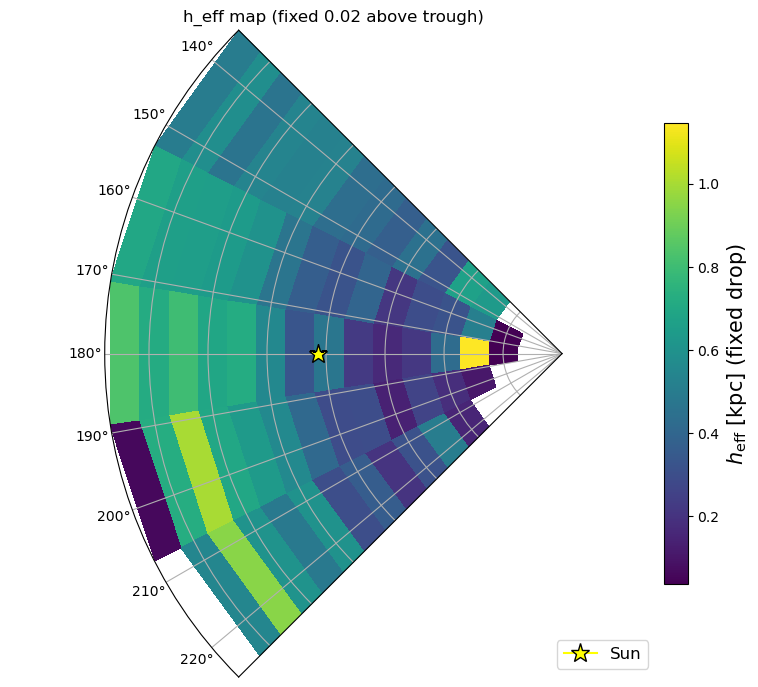

In [237]:
DROP_FIXED = 0.02  # fixed height above the trough, in [Mg/Fe]

def root_func_shifted(z, pars, drop=DROP_FIXED):
    peak = pars["A1"] + pars["A2"]
    Ystar = mixture_of_sech2(z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], pars["z0"])
    return (Ystar - peak) - drop

RESULTS_PATH_HEFF_MAP_FIXED = "heff_map_1kpc_fixed_drop.pkl"
FORCE_RERUN_HEFF_MAP_FIXED = True

if os.path.exists(RESULTS_PATH_HEFF_MAP_FIXED) and not FORCE_RERUN_HEFF_MAP_FIXED:
    with open(RESULTS_PATH_HEFF_MAP_FIXED, "rb") as f:
        saved = pickle.load(f)
    h_eff_med_map_fixed, h_eff_std_map_fixed = saved["h_eff_med_map"], saved["h_eff_std_map"]
    n_stars_map_fixed, ok_grid_heff_fixed = saved["n_stars_map"], saved["ok_grid_heff"]
    print(f"loaded results from {RESULTS_PATH_HEFF_MAP_FIXED}  ({int(ok_grid_heff_fixed.sum())}/{ok_grid_heff_fixed.size} cells)")
else:
    n_R_heff, n_seg_heff = len(R_edges) - 1, len(SEG_PLOT_heff)
    h_eff_med_map_fixed = np.full((n_R_heff, n_seg_heff), np.nan)
    h_eff_std_map_fixed = np.full((n_R_heff, n_seg_heff), np.nan)
    n_stars_map_fixed   = np.zeros((n_R_heff, n_seg_heff), dtype=int)
    ok_grid_heff_fixed  = np.zeros((n_R_heff, n_seg_heff), dtype=bool)

    key = jr.PRNGKey(0)
    pairs = list(product(range(n_R_heff), range(n_seg_heff)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
        seg_id = SEG_PLOT_heff[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment(
            R_star, Z_star, mgfe_star, mgfe_err_star, seg_mask=segm_heff[seg_id], Rmin=Rmin, Rmax=Rmax)
        n_stars_map_fixed[i_R, j_seg] = ns_k
        if not ok_k:
            continue
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()

            h_effs = []
            for i in range(256):
                cs = {kk: vv[i] for kk, vv in samples_k.items()}
                cs["h2"] = cs["h1"] + cs["d_h2"]
                hi = 8 * max(cs["h1"], cs["h2"])
                try:
                    zstar = brentq(root_func_shifted, cs["z0"] + 1e-9, hi, args=(cs,))
                    h_effs.append(zstar - cs["z0"])
                except ValueError:
                    continue
            if h_effs:
                h_effs = np.array(h_effs)
                h_eff_med_map_fixed[i_R, j_seg] = np.median(h_effs)
                pcl = np.percentile(h_effs, [16, 84])
                h_eff_std_map_fixed[i_R, j_seg] = 0.5 * (pcl[1] - pcl[0])
                ok_grid_heff_fixed[i_R, j_seg] = True
        except Exception as e:
            print(f"  fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 10 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    print("fits complete:", int(ok_grid_heff_fixed.sum()), "/", ok_grid_heff_fixed.size)
    with open(RESULTS_PATH_HEFF_MAP_FIXED, "wb") as f:
        pickle.dump({"h_eff_med_map": h_eff_med_map_fixed, "h_eff_std_map": h_eff_std_map_fixed,
                     "n_stars_map": n_stars_map_fixed, "ok_grid_heff": ok_grid_heff_fixed,
                     "R_edges": R_edges, "SEG_PLOT_heff": SEG_PLOT_heff,
                     "crowd_bounds_heff": np.asarray(crowd_bounds_heff)}, f)
    print(f"saved to {RESULTS_PATH_HEFF_MAP_FIXED}")

# --- plot: same polar style as your original h_eff map ---
theta_edges_heff = np.unwrap(np.array(crowd_bounds_heff, float))
for i in range(1, len(theta_edges_heff)):
    while theta_edges_heff[i] <= theta_edges_heff[i - 1]:
        theta_edges_heff[i] += 2 * np.pi

T_mesh_heff, R_mesh_heff = np.meshgrid(theta_edges_heff, R_edges)
Hmap_med_fixed = np.ma.masked_invalid(h_eff_med_map_fixed)
theta_min_h, theta_max_h = theta_edges_heff[0], theta_edges_heff[-1]
theta_sun, R_sun = np.radians(180), 8.275

fig = plt.figure(figsize=(8, 7))
ax = plt.subplot(1, 1, 1, projection="polar")
pcm = ax.pcolormesh(T_mesh_heff, R_mesh_heff, Hmap_med_fixed, cmap="viridis", shading="flat")
fig.colorbar(pcm, ax=ax, pad=0.01, shrink=0.7).set_label(r"$h_\mathrm{eff}$ [kpc] (fixed drop)", fontsize=15)
ax.set_theta_zero_location("E"); ax.set_theta_direction(1); ax.set_rmax(R_edges[-1])
ax.set_thetamin(np.degrees(theta_min_h)); ax.set_thetamax(np.degrees(theta_max_h))
ax.set_yticklabels([])
ax.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14, markeredgecolor="k", zorder=5, label="Sun")
ax.legend(loc="lower right", fontsize=12)
plt.title(f"h_eff map (fixed {DROP_FIXED} above trough)")
plt.tight_layout()
plt.show()

computed h_eff for 121/165 cells


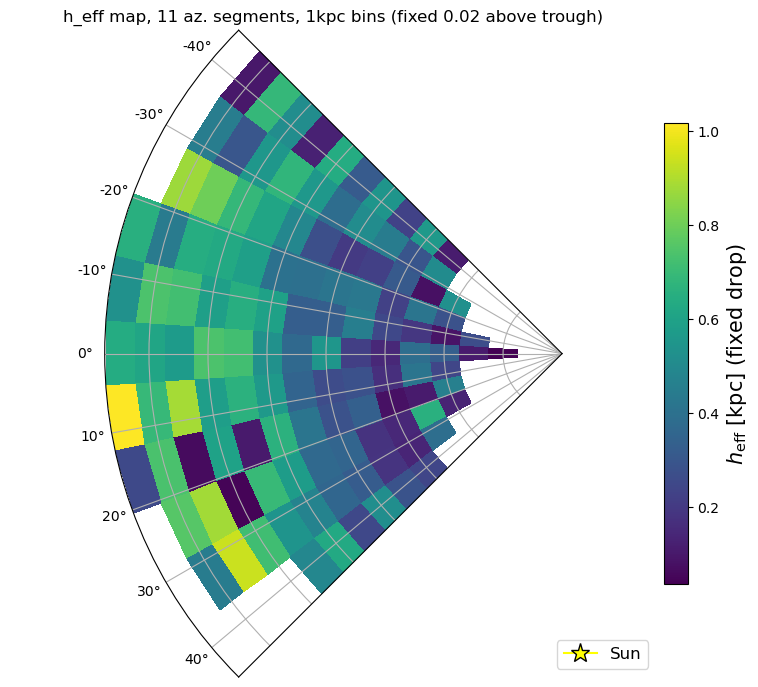

In [236]:
DROP_FIXED = 0.02

def root_func_shifted(z, pars, drop=DROP_FIXED):
    peak = pars["A1"] + pars["A2"]
    Ystar = mixture_of_sech2(z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], pars["z0"])
    return (Ystar - peak) - drop

h_eff_med_map = np.full((n_R, n_seg), np.nan)
h_eff_std_map = np.full((n_R, n_seg), np.nan)

for (i_R, j_seg), cell in per_cell.items():
    s = cell["samples"]
    n_draws = min(256, len(s["z0"]))
    h_effs = []
    for i in range(n_draws):
        cs = {k: v[i] for k, v in s.items()}
        cs["h2"] = cs["h1"] + cs["d_h2"]
        hi = 8 * max(cs["h1"], cs["h2"])
        try:
            zstar = brentq(root_func_shifted, cs["z0"] + 1e-9, hi, args=(cs,))
            h_effs.append(zstar - cs["z0"])
        except ValueError:
            continue
    if h_effs:
        h_effs = np.array(h_effs)
        h_eff_med_map[i_R, j_seg] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std_map[i_R, j_seg] = 0.5 * (pcl[1] - pcl[0])

print(f"computed h_eff for {np.isfinite(h_eff_med_map).sum()}/{h_eff_med_map.size} cells")

# --- plot (theta_edges already built the same way earlier in your notebook) ---
T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
Hmap_med = np.ma.masked_invalid(h_eff_med_map)
theta_sun, R_sun = np.radians(180), 8.275

fig = plt.figure(figsize=(8, 7))
ax = plt.subplot(1, 1, 1, projection="polar")
pcm = ax.pcolormesh(T_mesh, R_mesh, Hmap_med, cmap="viridis", shading="flat")
fig.colorbar(pcm, ax=ax, pad=0.01, shrink=0.7).set_label(r"$h_\mathrm{eff}$ [kpc] (fixed drop)", fontsize=15)
ax.set_theta_zero_location("W"); ax.set_theta_direction(1); ax.set_rmax(R_edges[-1])
ax.set_thetamin(np.degrees(theta_edges[0])); ax.set_thetamax(np.degrees(theta_edges[-1]))
ax.set_yticklabels([])
ax.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14, markeredgecolor="k", zorder=5, label="Sun")
ax.legend(loc="lower right", fontsize=12)
plt.title(f"h_eff map, 11 az. segments, 1kpc bins (fixed {DROP_FIXED} above trough)")
plt.tight_layout()
plt.show()